# **UTS DATA WRANGLING**
### Harga Pangan Jawa Timur 2024

Nama: Adel Phonsa Jeanne Valencya Sihombing

NIM: 25031554073

Kelas: 2025G

Paket: C

### Tahap 1 — PLAN WRANGLING

#### 1.1 Tujuan analisis
Analisis ini bertujuan untuk mengetahui kabupaten/kota yang mengalami kenaikan harga pangan terbesar dari Januari hingga Desember 2024 pada lima komoditas Paket C, yaitu beras medium I, cabai rawit merah, bawang putih, gula pasir lokal, dan daging ayam ras.
Selain itu, analisis dilakukan untuk mengetahui apakah besarnya kenaikan harga pangan memiliki hubungan dengan kepadatan penduduk atau jumlah kecamatan dan kelurahan/desa di setiap wilayah.

#### 1.2 Kebutuhan data
dibutuhkan tiga sumber data:
1. **Data Harga Pangan (PIHPS):** digunakan untuk memperoleh informasi harga harian lima komoditas pangan di pasar tradisional selama tahun 2024.
2. **Data Cuaca (NOAA GSOD):** digunakan untuk memperoleh informasi kondisi cuaca harian dari stasiun pengamatan di Jawa Timur.
3. **Data Wilayah:** digunakan untuk memperoleh informasi kode wilayah, luas wilayah, jumlah penduduk, serta jumlah kecamatan dan kelurahan/desa.

#### 1.3 Variabel yang digunakan
Variabel yang dibutuhkan meliputi:
- Kode dan nama kabupaten/kota.
- Nama komoditas pangan.
- Tanggal pengamatan.
- Harga pangan.
- Temperatur dan curah hujan.
- Luas wilayah.
- Jumlah penduduk.
- Kepadatan penduduk.
- Jumlah kecamatan.
- Jumlah kelurahan/desa.

#### 1.4 Unit observasi dataset akhir
Unit observasi dataset akhir berupa satu baris untuk setiap kombinasi wilayah, komoditas, dan tanggal pengamatan. Data harga pangan dan cuaca disusun berdasarkan tanggal harian, sedangkan data kependudukan dan administrasi wilayah digunakan sebagai informasi tambahan yang melekat pada setiap wilayah.

#### 1.5 Rencana alur pengerjaan
**1. Discovery**

Pada tahap ini, dilakukan pemeriksaan terhadap ketiga sumber data, yaitu data harga pangan PIHPS, data cuaca NOAA GSOD, dan data wilayah. Pemeriksaan meliputi format file, struktur tabel, periode data, variabel yang tersedia, serta kondisi awal dari masing-masing data.

**2. Structuring**

Pada tahap ini, data mulai dibaca dan disusun agar lebih mudah diolah dan dianalisis. Data harga pangan yang awalnya berbentuk wide diubah menjadi long. Data cuaca disusun berdasarkan tanggal dan stasiun pengamatan, sedangkan data wilayah disiapkan berdasarkan kode kabupaten/kota.

**3. Cleaning**

Pada tahap ini, dilakukan pemeriksaan dan perbaikan terhadap kualitas data. Prosesnya meliputi penyesuaian tipe data, penanganan nilai kosong dan kode khusus, pemeriksaan data duplikat, serta identifikasi nilai yang tidak wajar. Selain itu, satuan pada data cuaca juga disesuaikan agar lebih mudah dipahami.

**4. Enriching**

Pada tahap ini, ketiga sumber data mulai digabungkan, yaitu data harga pangan, cuaca, dan wilayah. Penggabungan dilakukan menggunakan kode wilayah dan tanggal pengamatan. Data wilayah juga dilengkapi dengan informasi luas wilayah, jumlah penduduk, kepadatan penduduk, jumlah kecamatan, serta jumlah kelurahan/desa.

**5. Validating**

Pada tahap ini, dilakukan pengecekan kembali untuk memastikan data yang sudah digabungkan memiliki hasil yang sesuai. Pemeriksaan meliputi jumlah baris dan kolom, kesesuaian kode wilayah, jumlah data kosong, data duplikat, serta konsistensi nilai dan tipe data.

**6. Publishing**

Pada tahap yang terakhir, dataset yang sudah melalui proses pengolahan dan pemeriksaan disimpan dalam format CSV. Dataset ini kemudian digunakan sebagai dasar untuk melakukan analisis kenaikan harga pangan dan melihat hubungannya dengan karakteristik wilayah di Jawa Timur.

![Diagram Alur Data Wrangling](../diagram_wrangling.png)

### Tahap 2 — Data Inventory.
##### 2.a Tabel inventaris ketiga sumber

In [2]:
%pip install pandas openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\ASUS\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path
import pandas as pd
import os

# Menentukan lokasi folder data mentah
data_raw = Path("..") / "data_raw"

# Menampilkan seluruh file dalam folder data_raw
for file in sorted(data_raw.rglob("*")):
    if file.is_file():
        print(file.relative_to(data_raw))


.DS_Store
1_harga_pasar_tradisional\pihps_pasar_tradisional_jatim_2024.xlsx
1_harga_pasar_tradisional\pihps_pasar_tradisional_jatim_2025H1.xlsx
2_cuaca_stasiun\noaa_gsod_jatim_2024.csv
3_wilayah\kode_wilayah_jatim.csv
3_wilayah\luas_jatim.csv
3_wilayah\penduduk_jatim.csv
PETUNJUK.md
SUMBER_DATA.md


In [4]:
# Inventarisasi ukuran seluruh sheet PIHPS 2024
file_excel_2024 = (
    data_raw / "1_harga_pasar_tradisional"
    / "pihps_pasar_tradisional_jatim_2024.xlsx"
)

excel = pd.ExcelFile(file_excel_2024)
hasil_sheet = []

for sheet in excel.sheet_names:
    df = pd.read_excel(
        file_excel_2024,
        sheet_name=sheet
    )

    hasil_sheet.append({
        "Wilayah": sheet,
        "Jumlah Baris": df.shape[0],
        "Jumlah Kolom": df.shape[1]
    })
tabel_sheet = pd.DataFrame(hasil_sheet)
display(tabel_sheet)

,Wilayah,Jumlah Baris,Jumlah Kolom
0,Kab. Banyuwangi,28,265
1,Kab. Jember,27,265
2,Kab. Sumenep,31,265
3,Kota Blitar,30,265
4,Kota Kediri,29,265
5,Kota Madiun,29,265
6,Kota Malang,31,265
7,Kota Probolinggo,30,265
8,Kota Surabaya,31,265


In [5]:
# Membaca data cuaca NOAA
file_cuaca = data_raw / "2_cuaca_stasiun" / "noaa_gsod_jatim_2024.csv"
df_cuaca = pd.read_csv(file_cuaca)

print("Ukuran data cuaca:", df_cuaca.shape)
print("\nNama kolom:")
print(df_cuaca.columns.tolist())
display(df_cuaca.head())

Ukuran data cuaca: (1228, 19)

Nama kolom:
['STATION', 'NAME', 'LATITUDE', 'LONGITUDE', 'ELEVATION', 'DATE', 'DEWP', 'FRSHTT', 'GUST', 'MAX', 'MIN', 'MXSPD', 'PRCP', 'SLP', 'SNDP', 'STP', 'TEMP', 'VISIB', 'WDSP']


,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,DEWP,FRSHTT,GUST,MAX,MIN,MXSPD,PRCP,SLP,SNDP,STP,TEMP,VISIB,WDSP
0,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-02,77.4,0,999.9,94.3,81.3,5.1,0.00,1008.4,999.9,7.9,86.5,5.9,2.8
1,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-05,76.8,0,999.9,92.8,78.6,8.0,0.00,1009.9,999.9,9.4,83.9,5.1,2.6
2,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-06,76.8,10000,999.9,89.8,79.0,8.0,0.04,1009.8,999.9,9.4,84.3,5.6,2.0
3,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-08,76.9,0,999.9,90.3,79.5,7.0,0.00,1010.3,999.9,9.9,84.0,5.4,3.8
4,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-10,77.3,0,999.9,95.4,82.0,11.1,0.00,1007.8,999.9,7.4,87.9,6.1,6.4


In [6]:
# Membaca data wilayah kepmendagri
file_kode = data_raw / "3_wilayah" / "kode_wilayah_jatim.csv"
file_luas = data_raw / "3_wilayah" / "luas_jatim.csv"
file_penduduk = data_raw / "3_wilayah" / "penduduk_jatim.csv"

df_kode = pd.read_csv(file_kode)
df_luas = pd.read_csv(file_luas)
df_penduduk = pd.read_csv(file_penduduk)

print("KODE WILAYAH:", df_kode.shape)
display(df_kode.head())

print("LUAS WILAYAH JATIM:", df_luas.shape)
display(df_luas.head())

print("DATA PENDUDUK:", df_penduduk.shape)
display(df_penduduk.head())

KODE WILAYAH: (9199, 2)


,kode,nama
0,35,Jawa Timur
1,35.01,Kabupaten Pacitan
2,35.01.01,Donorojo
3,35.01.01.2001,Widoro
4,35.01.01.2002,Sawahan


LUAS WILAYAH JATIM: (39, 3)


,kode,nama,luas
0,35.00,Jawa Timur,48055.876
1,35.01,Kabupaten Pacitan,1434.818
2,35.02,Kabupaten Ponorogo,1418.618
3,35.03,Kabupaten Trenggalek,1249.367
4,35.04,Kabupaten Tulungagung,1144.856


DATA PENDUDUK: (39, 5)


,kode,nama,pria,wanita,total
0,35.00,Jawa Timur,20894359,21025547,41919906
1,35.01,Kabupaten Pacitan,294808,293910,588718
2,35.02,Kabupaten Ponorogo,486147,492861,979008
3,35.03,Kabupaten Trenggalek,378680,375130,753810
4,35.04,Kabupaten Tulungagung,570819,568405,1139224


##### 2.b Analisis perbedaan struktur ketiga sumber data

Ketiga sumber data yang digunakan memiliki struktur penyimpanan yang berbeda sehingga memerlukan penanganan yang berbeda.

**a. Data Harga Pangan PIHPS**

Data harga pangan PIHPS disimpan dalam format Excel dengan sembilan sheet yang mewakili sembilan kabupaten/kota di Jawa Timur. Setiap sheet memiliki 265 kolom, terdiri atas kolom identitas komoditas dan kolom tanggal pengamatan. Dengan demikian, tanggal pengamatan disajikan secara melebar (*wide format*), yaitu satu tanggal menempati satu kolom.
Struktur tersebut menyebabkan data perlu diubah menjadi format memanjang (*long format*) agar setiap baris mewakili satu pengamatan harga berdasarkan wilayah, komoditas, dan tanggal. Selain itu, nama sheet perlu disesuaikan dengan kode wilayah agar dapat diintegrasikan dengan data Kepmendagri.

**b. Data Cuaca NOAA GSOD**

Data cuaca NOAA GSOD disimpan dalam format CSV dengan struktur kolom yang konsisten. File ini memiliki 1.228 baris dan 19 kolom. Setiap baris mewakili pengamatan cuaca harian pada suatu stasiun pengamatan.
Data cuaca memiliki kode khusus untuk menunjukkan nilai yang tidak tersedia, seperti 999.9 pada beberapa kolom dan 99.99 pada kolom curah hujan. Oleh karena itu, kode tersebut perlu diidentifikasi dan ditangani agar tidak dianggap sebagai nilai pengamatan yang sebenarnya. Data juga memerlukan penyesuaian identitas stasiun dengan wilayah yang sesuai sebelum diintegrasikan dengan data harga pangan.

**c. Data Wilayah Kepmendagri**

Data wilayah Kepmendagri terdiri atas tiga file CSV, yaitu data kode wilayah, luas wilayah, dan jumlah penduduk. Ketiga file memiliki jumlah baris dan kolom yang berbeda. Data kode wilayah memiliki 9.199 baris dan 2 kolom, data luas wilayah memiliki 39 baris dan 3 kolom, sedangkan data penduduk memiliki 39 baris dan 5 kolom.
Struktur kode wilayah disusun secara hierarkis, mulai dari provinsi, kabupaten/kota, kecamatan, hingga desa/kelurahan. Sementara itu, data luas wilayah dan jumlah penduduk tersedia pada tingkat provinsi serta kabupaten/kota. Kolom kode wilayah dapat digunakan sebagai kunci penghubung (*key*) untuk menggabungkan data luas wilayah dan penduduk. Data ini juga digunakan untuk memperkaya data harga pangan melalui penambahan informasi wilayah.

### Tahap 3 – Read & Structure
##### 3.a Membaca seluruh sumber data

In [7]:
# Membaca Excel PIHPS 2024
file_excel_2024 = (
    data_raw / "1_harga_pasar_tradisional"
    / "pihps_pasar_tradisional_jatim_2024.xlsx"
)

excel = pd.ExcelFile(file_excel_2024)
data_pihps_2024 = {}

for sheet in excel.sheet_names:
    data_pihps_2024[sheet] = pd.read_excel(
        file_excel_2024,
        sheet_name=sheet
    )


# Membaca CSV NOAA
file_cuaca = (
    data_raw / "2_cuaca_stasiun"
    / "noaa_gsod_jatim_2024.csv"
)

df_cuaca = pd.read_csv(file_cuaca)


# Membaca CSV Kepmendagri
folder_wilayah = data_raw / "3_wilayah"

df_kode = pd.read_csv(
    folder_wilayah / "kode_wilayah_jatim.csv",
    dtype={"kode": "string"}
)

df_luas = pd.read_csv(
    folder_wilayah / "luas_jatim.csv",
    dtype={"kode": "string"}
)

df_penduduk = pd.read_csv(
    folder_wilayah / "penduduk_jatim.csv",
    dtype={"kode": "string"}
)


# Menampilkan jumlah baris dan kolom
# Data PIHPS
daftar_pihps = []
for wilayah, df in data_pihps_2024.items():
    daftar_pihps.append({
        "Wilayah": wilayah,
        "Jumlah Baris": df.shape[0],
        "Jumlah Kolom": df.shape[1]
    })

tabel_pihps = pd.DataFrame(daftar_pihps)
display(tabel_pihps)

# Data NOAA
tabel_noaa = pd.DataFrame({
    "Sumber Data": ["NOAA GSOD"],
    "Jumlah Baris": [df_cuaca.shape[0]],
    "Jumlah Kolom": [df_cuaca.shape[1]]
})
display(tabel_noaa)

# Data Kepmendagri
tabel_kemendagri = pd.DataFrame([
    {
        "Nama Data": "Kode Wilayah",
        "Jumlah Baris": df_kode.shape[0],
        "Jumlah Kolom": df_kode.shape[1]
    },
    {
        "Nama Data": "Luas Wilayah",
        "Jumlah Baris": df_luas.shape[0],
        "Jumlah Kolom": df_luas.shape[1]
    },
    {
        "Nama Data": "Penduduk",
        "Jumlah Baris": df_penduduk.shape[0],
        "Jumlah Kolom": df_penduduk.shape[1]
    }
])

display(tabel_kemendagri)

,Wilayah,Jumlah Baris,Jumlah Kolom
0,Kab. Banyuwangi,28,265
1,Kab. Jember,27,265
2,Kab. Sumenep,31,265
3,Kota Blitar,30,265
4,Kota Kediri,29,265
5,Kota Madiun,29,265
6,Kota Malang,31,265
7,Kota Probolinggo,30,265
8,Kota Surabaya,31,265


,Sumber Data,Jumlah Baris,Jumlah Kolom
0,NOAA GSOD,1228,19


,Nama Data,Jumlah Baris,Jumlah Kolom
0,Kode Wilayah,9199,2
1,Luas Wilayah,39,3
2,Penduduk,39,5


##### 3.b Mengubah format wide menjadi long

In [8]:
# Melihat 15 baris pertama data PIHPS
display(data_pihps_2024["Kab. Banyuwangi"].head(15))

,no,name,level,01/01/2024,02/01/2024,03/01/2024,04/01/2024,05/01/2024,08/01/2024,09/01/2024,...,18/12/2024,19/12/2024,20/12/2024,23/12/2024,24/12/2024,25/12/2024,26/12/2024,27/12/2024,30/12/2024,31/12/2024
0,I,Beras,1,"13,250","13,250","13,250","13,250","13,250","13,250","13,250",...,"13,550","13,550","13,550","13,550","13,550","13,550","13,550","13,550","13,550","13,550"
1,1,Beras Kualitas Medium I,2,"12,900","12,900","12,900","12,900","12,900","12,900","12,900",...,"13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,250"
2,2,Beras Kualitas Medium II,2,"12,000","12,000","12,000","12,000","12,000","12,000","12,000",...,"12,000","12,000","12,000","12,000","12,000","12,000","12,000","12,000","12,000","12,000"
3,3,Beras Kualitas Super I,2,"14,500","14,500","14,500","14,500","14,500","14,500","14,500",...,"15,000","15,000","15,000","15,000","15,000","15,000","15,000","15,000","15,000","15,000"
4,4,Beras Kualitas Super II,2,"14,150","14,150","14,150","14,150","14,150","14,150","14,150",...,"14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500"
5,II,Daging Ayam,1,"29,500","28,750","28,000","28,750","28,750","28,250","28,250",...,"30,000","30,000","31,250","31,000","32,000","32,000","32,000","33,000","33,250","33,250"
6,1,Daging Ayam Ras Segar,2,"29,500","28,750","28,000","28,750","28,750","28,250","28,250",...,"30,000","30,000","31,250","31,000","32,000","32,000","32,000","33,000","33,250","33,250"
7,III,Daging Sapi,1,"122,500","122,500","122,500","122,500","122,500","122,500","122,500",...,"127,500","127,500","127,500","127,500","127,500","127,500","127,500","127,500","127,500","127,500"
8,1,Daging Sapi Kualitas 1,2,"125,000","125,000","125,000","125,000","125,000","125,000","125,000",...,"130,000","130,000","130,000","130,000","130,000","130,000","130,000","130,000","130,000","130,000"
9,2,Daging Sapi Kualitas 2,2,"120,000","120,000","120,000","120,000","120,000","120,000","120,000",...,"125,000","125,000","125,000","125,000","125,000","125,000","125,000","125,000","125,000","125,000"


In [9]:
# Melihat daftar nama komoditas pada PIHPS
komoditas = data_pihps_2024["Kab. Banyuwangi"]

display(
    komoditas.loc[
        komoditas["level"] == 2,
        ["no", "name", "level"]
    ].reset_index(drop=True)
)

,no,name,level
0,1,Beras Kualitas Medium I,2
1,2,Beras Kualitas Medium II,2
2,3,Beras Kualitas Super I,2
3,4,Beras Kualitas Super II,2
4,1,Daging Ayam Ras Segar,2
5,1,Daging Sapi Kualitas 1,2
6,2,Daging Sapi Kualitas 2,2
7,1,Telur Ayam Ras Segar,2
8,1,Bawang Merah Ukuran Sedang,2
9,1,Bawang Putih Ukuran Sedang,2


In [10]:
# Daftar 5 komoditas Paket C
komoditas_paket_c = [
    "Beras Kualitas Medium I",
    "Cabai Rawit Merah",
    "Bawang Putih Ukuran Sedang",
    "Gula Pasir Lokal",
    "Daging Ayam Ras Segar"
]

# Memeriksa apakah kelima komoditas tersedia
for nama in komoditas_paket_c:
    print(nama, ":", nama in komoditas["name"].values)

Beras Kualitas Medium I : True
Cabai Rawit Merah : True
Bawang Putih Ukuran Sedang : True
Gula Pasir Lokal : True
Daging Ayam Ras Segar : True


In [11]:
# Mengambil data Banyuwangi
df_banyuwangi = data_pihps_2024["Kab. Banyuwangi"].copy()

# Memisahkan baris komoditas Paket C
df_banyuwangi = df_banyuwangi[
    (df_banyuwangi["level"] == 2) &
    (df_banyuwangi["name"].isin(komoditas_paket_c))
].copy()

# Mengubah format wide menjadi long
kolom_identitas = ["no", "name", "level"]
df_banyuwangi_long = df_banyuwangi.melt(
    id_vars=kolom_identitas,
    var_name="tanggal",
    value_name="harga"
)

# Menambahkan nama wilayah
df_banyuwangi_long["wilayah"] = "Kab. Banyuwangi"

# Mengganti nama kolom name menjadi komoditas
df_banyuwangi_long = df_banyuwangi_long.rename(
    columns={"name": "komoditas"}
)

# Menampilkan hasil
display(df_banyuwangi_long.head(10))

,no,komoditas,level,tanggal,harga,wilayah
0,1,Beras Kualitas Medium I,2,01/01/2024,"12,900",Kab. Banyuwangi
1,1,Daging Ayam Ras Segar,2,01/01/2024,"29,500",Kab. Banyuwangi
2,1,Bawang Putih Ukuran Sedang,2,01/01/2024,"33,500",Kab. Banyuwangi
3,2,Cabai Rawit Merah,2,01/01/2024,"70,500",Kab. Banyuwangi
4,2,Gula Pasir Lokal,2,01/01/2024,"16,500",Kab. Banyuwangi
5,1,Beras Kualitas Medium I,2,02/01/2024,"12,900",Kab. Banyuwangi
6,1,Daging Ayam Ras Segar,2,02/01/2024,"28,750",Kab. Banyuwangi
7,1,Bawang Putih Ukuran Sedang,2,02/01/2024,"33,500",Kab. Banyuwangi
8,2,Cabai Rawit Merah,2,02/01/2024,"62,500",Kab. Banyuwangi
9,2,Gula Pasir Lokal,2,02/01/2024,"16,500",Kab. Banyuwangi


In [12]:
# Menyiapkan daftar untuk menyimpan hasil setiap wilayah
daftar_data_long = []

# Memproses seluruh sheet PIHPS
for wilayah, df in data_pihps_2024.items():

    # Mengambil 5 komoditas Paket C
    df_pilih = df[
        (df["level"] == 2) &
        (df["name"].isin(komoditas_paket_c))
    ].copy()

    # Mengubah format wide menjadi long
    df_long = df_pilih.melt(
        id_vars=["no", "name", "level"],
        var_name="tanggal",
        value_name="harga"
    )

    # Menambahkan nama wilayah
    df_long["wilayah"] = wilayah

    # Mengganti nama kolom
    df_long = df_long.rename(
        columns={"name": "komoditas"}
    )

    # Menyimpan hasil
    daftar_data_long.append(df_long)

# Menggabungkan seluruh wilayah
df_pihps_long = pd.concat(
    daftar_data_long,
    ignore_index=True
)

# Menampilkan hasil
display(df_pihps_long.head(10))

,no,komoditas,level,tanggal,harga,wilayah
0,1,Beras Kualitas Medium I,2,01/01/2024,"12,900",Kab. Banyuwangi
1,1,Daging Ayam Ras Segar,2,01/01/2024,"29,500",Kab. Banyuwangi
2,1,Bawang Putih Ukuran Sedang,2,01/01/2024,"33,500",Kab. Banyuwangi
3,2,Cabai Rawit Merah,2,01/01/2024,"70,500",Kab. Banyuwangi
4,2,Gula Pasir Lokal,2,01/01/2024,"16,500",Kab. Banyuwangi
5,1,Beras Kualitas Medium I,2,02/01/2024,"12,900",Kab. Banyuwangi
6,1,Daging Ayam Ras Segar,2,02/01/2024,"28,750",Kab. Banyuwangi
7,1,Bawang Putih Ukuran Sedang,2,02/01/2024,"33,500",Kab. Banyuwangi
8,2,Cabai Rawit Merah,2,02/01/2024,"62,500",Kab. Banyuwangi
9,2,Gula Pasir Lokal,2,02/01/2024,"16,500",Kab. Banyuwangi


In [13]:
# Memeriksa jumlah wilayah yang berhasil digabung
print("Jumlah wilayah:", df_pihps_long["wilayah"].nunique())

# Menampilkan daftar seluruh wilayah
display(
    df_pihps_long["wilayah"]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Memeriksa ukuran tabel gabungan
print("Ukuran tabel:", df_pihps_long.shape)

Jumlah wilayah: 9


0     Kab. Banyuwangi
1         Kab. Jember
2        Kab. Sumenep
3         Kota Blitar
4         Kota Kediri
5         Kota Madiun
6         Kota Malang
7    Kota Probolinggo
8       Kota Surabaya
Name: wilayah, dtype: str

Ukuran tabel: (11790, 6)


##### 3.c Konversi tipe data

In [14]:
print(df_pihps_long.dtypes)

no           object
komoditas       str
level         int64
tanggal         str
harga           str
wilayah         str
dtype: object


In [15]:
# Mengubah kolom tanggal menjadi tipe datetime
df_pihps_long["tanggal"] = pd.to_datetime(
    df_pihps_long["tanggal"],
    format="%d/%m/%Y",
    errors="coerce"
)
print(df_pihps_long["tanggal"].dtype)
display(df_pihps_long[["tanggal"]].head())

datetime64[us]


,tanggal
0,2024-01-01
1,2024-01-01
2,2024-01-01
3,2024-01-01
4,2024-01-01


In [16]:
# Mengubah kolom harga menjadi tipe numerik
df_pihps_long["harga"] = (
    df_pihps_long["harga"]
    .str.replace(",", "", regex=False)
    .str.strip()
)
df_pihps_long["harga"] = pd.to_numeric(
    df_pihps_long["harga"],
    errors="coerce"
)
print(df_pihps_long["harga"].dtype)
display(df_pihps_long[["harga"]].head())

float64


,harga
0,12900.0
1,29500.0
2,33500.0
3,70500.0
4,16500.0


In [17]:
# Memastikan tidak ada nilai kosong pada kolom tanggal dan harga
print("Tanggal kosong:", df_pihps_long["tanggal"].isna().sum())
print("Harga kosong:", df_pihps_long["harga"].isna().sum())

Tanggal kosong: 0
Harga kosong: 110


In [18]:
# Memeriksa nilai harga kosong
display(
    df_pihps_long[df_pihps_long["harga"].isna()]
    [["wilayah", "komoditas", "tanggal", "harga"]]
    .head(10)
)

,wilayah,komoditas,tanggal,harga
555,Kab. Banyuwangi,Beras Kualitas Medium I,2024-06-04,NaN
556,Kab. Banyuwangi,Daging Ayam Ras Segar,2024-06-04,NaN
557,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,2024-06-04,NaN
558,Kab. Banyuwangi,Cabai Rawit Merah,2024-06-04,NaN
559,Kab. Banyuwangi,Gula Pasir Lokal,2024-06-04,NaN
640,Kab. Banyuwangi,Beras Kualitas Medium I,2024-06-27,NaN
641,Kab. Banyuwangi,Daging Ayam Ras Segar,2024-06-27,NaN
642,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,2024-06-27,NaN
643,Kab. Banyuwangi,Cabai Rawit Merah,2024-06-27,NaN
644,Kab. Banyuwangi,Gula Pasir Lokal,2024-06-27,NaN


In [19]:
# Memeriksa tipe data kode wilayah, luas wilayah, dan data penduduk (kepmendagri)
print("Kode wilayah :", df_kode["kode"].dtype)
print("Luas wilayah :", df_luas["kode"].dtype)
print("Data penduduk:", df_penduduk["kode"].dtype)

display(df_kode.head())

Kode wilayah : string
Luas wilayah : string
Data penduduk: string


,kode,nama
0,35,Jawa Timur
1,35.01,Kabupaten Pacitan
2,35.01.01,Donorojo
3,35.01.01.2001,Widoro
4,35.01.01.2002,Sawahan


##### 3.c Konversi tipe data dan penanganan masalah

Pada tahap ini, ditemukan beberapa masalah pada tipe data yang perlu diperbaiki. Pertama, kolom harga pada data PIHPS masih berbentuk teks dan menggunakan tanda koma sebagai pemisah ribuan, seperti "12,900". Untuk mengatasinya, tanda koma dan spasi dihapus, kemudian data diubah menjadi tipe numerik menggunakan `pd.to_numeric()`.

Kedua, kolom tanggal masih berbentuk teks dengan format DD/MM/YYYY. Kolom ini kemudian diubah menjadi tipe datetime menggunakan `pd.to_datetime()`. Setelah diperiksa, seluruh tanggal berhasil dikonversi tanpa ada nilai yang gagal.

Ketiga, kode wilayah pada data Kepmendagri dipertahankan dalam bentuk teks (string). Hal ini dilakukan agar format kode seperti 35.10 dan 35.01.01 tidak berubah jika terbaca sebagai angka.

Selain itu, ditemukan 110 nilai harga kosong pada data PIHPS. Nilai tersebut tetap dibiarkan sebagai `NaN` dan tidak langsung diisi atau dihapus agar data asli tetap terjaga. Penanganannya akan dilakukan pada tahap pembersihan data.

### Tahap 4 — Integrasi Data
##### 4.a Membuat tabel referensi wilayah.

In [20]:
# Memeriksa struktur data kepmendagri
print("DATA KODE WILAYAH")
display(df_kode.head())

print("DATA LUAS WILAYAH")
display(df_luas.head())

print("DATA PENDUDUK")
display(df_penduduk.head())

DATA KODE WILAYAH


,kode,nama
0,35,Jawa Timur
1,35.01,Kabupaten Pacitan
2,35.01.01,Donorojo
3,35.01.01.2001,Widoro
4,35.01.01.2002,Sawahan


DATA LUAS WILAYAH


,kode,nama,luas
0,35,Jawa Timur,48055.876
1,35.01,Kabupaten Pacitan,1434.818
2,35.02,Kabupaten Ponorogo,1418.618
3,35.03,Kabupaten Trenggalek,1249.367
4,35.04,Kabupaten Tulungagung,1144.856


DATA PENDUDUK


,kode,nama,pria,wanita,total
0,35,Jawa Timur,20894359,21025547,41919906
1,35.01,Kabupaten Pacitan,294808,293910,588718
2,35.02,Kabupaten Ponorogo,486147,492861,979008
3,35.03,Kabupaten Trenggalek,378680,375130,753810
4,35.04,Kabupaten Tulungagung,570819,568405,1139224


In [21]:
# Mengambil data kabupaten/kota 
df_kab_kota = df_kode[
    df_kode["kode"].str.match(r"^35\.\d{2}$")
].copy()
# Menggabungkan data luas wilayah
df_ref_wilayah = df_kab_kota.merge(
    df_luas[["kode", "luas"]],
    on="kode",
    how="left"
)
# Menggabungkan data penduduk
df_ref_wilayah = df_ref_wilayah.merge(
    df_penduduk[["kode", "total"]],
    on="kode",
    how="left"
)
# Mengubah luas dan jumlah penduduk menjadi numerik
df_ref_wilayah["luas"] = pd.to_numeric(
    df_ref_wilayah["luas"],
    errors="coerce"
)
df_ref_wilayah["total"] = pd.to_numeric(
    df_ref_wilayah["total"],
    errors="coerce"
)
display(df_ref_wilayah.head(10))
print("Jumlah kabupaten/kota:", len(df_ref_wilayah))

,kode,nama,luas,total
0,35.01,Kabupaten Pacitan,1434.818,588718
1,35.02,Kabupaten Ponorogo,1418.618,979008
2,35.03,Kabupaten Trenggalek,1249.367,753810
3,35.04,Kabupaten Tulungagung,1144.856,1139224
4,35.05,Kabupaten Blitar,1745.383,1261699
5,35.06,Kabupaten Kediri,1523.563,1691976
6,35.07,Kabupaten Malang,3473.747,2734623
7,35.08,Kabupaten Lumajang,1796.489,1116231
8,35.09,Kabupaten Jember,3314.358,2615874
9,35.10,Kabupaten Banyuwangi,3593.849,1791789


Jumlah kabupaten/kota: 38


In [22]:
import pandas as pd
[name for name, obj in globals().items()
 if isinstance(obj, pd.DataFrame)]

['df',
 'tabel_sheet',
 'df_cuaca',
 'df_kode',
 'df_luas',
 'df_penduduk',
 'tabel_pihps',
 'tabel_noaa',
 'tabel_kemendagri',
 'komoditas',
 'df_banyuwangi',
 'df_banyuwangi_long',
 'df_pilih',
 'df_long',
 'df_pihps_long',
 'df_kab_kota',
 'df_ref_wilayah']

In [23]:
# Mengambil data kecamatan
df_kecamatan = df_kode[
    df_kode["kode"].str.fullmatch(r"35\.\d{2}\.\d{2}")
].copy()

# Mengambil data kelurahan
df_kelurahan = df_kode[
    df_kode["kode"].str.fullmatch(r"35\.\d{2}\.\d{2}\.1\d{3}")
].copy()

# Mengambil data desa
df_desa = df_kode[
    df_kode["kode"].str.fullmatch(r"35\.\d{2}\.\d{2}\.2\d{3}")
].copy()

# Membuat kode kabupaten/kota
for df in [df_kecamatan, df_kelurahan, df_desa]:
    df["kode_kab_kota"] = (
        df["kode"].str.split(".").str[:2].str.join(".")
    )

# Menghitung jumlah masing-masing
jumlah_kecamatan = (
    df_kecamatan.groupby("kode_kab_kota")
    .size().reset_index(name="jumlah_kecamatan")
)

jumlah_kelurahan = (
    df_kelurahan.groupby("kode_kab_kota")
    .size().reset_index(name="jumlah_kelurahan")
)

jumlah_desa = (
    df_desa.groupby("kode_kab_kota")
    .size().reset_index(name="jumlah_desa")
)

In [24]:
# Menggabungkan jumlah kecamatan, kelurahan, dan desa
df_ref_wilayah = df_ref_wilayah.merge(
    jumlah_kecamatan,
    left_on="kode",
    right_on="kode_kab_kota",
    how="left"
).drop(columns="kode_kab_kota")

df_ref_wilayah = df_ref_wilayah.merge(
    jumlah_kelurahan,
    left_on="kode",
    right_on="kode_kab_kota",
    how="left"
).drop(columns="kode_kab_kota")

df_ref_wilayah = df_ref_wilayah.merge(
    jumlah_desa,
    left_on="kode",
    right_on="kode_kab_kota",
    how="left"
).drop(columns="kode_kab_kota")

display(df_ref_wilayah.head(10))

,kode,nama,luas,total,jumlah_kecamatan,jumlah_kelurahan,jumlah_desa
0,35.01,Kabupaten Pacitan,1434.818,588718,12,5,167.0
1,35.02,Kabupaten Ponorogo,1418.618,979008,21,26,281.0
2,35.03,Kabupaten Trenggalek,1249.367,753810,14,5,152.0
3,35.04,Kabupaten Tulungagung,1144.856,1139224,19,14,257.0
4,35.05,Kabupaten Blitar,1745.383,1261699,22,28,220.0
5,35.06,Kabupaten Kediri,1523.563,1691976,26,1,343.0
6,35.07,Kabupaten Malang,3473.747,2734623,33,12,378.0
7,35.08,Kabupaten Lumajang,1796.489,1116231,21,7,198.0
8,35.09,Kabupaten Jember,3314.358,2615874,31,22,226.0
9,35.10,Kabupaten Banyuwangi,3593.849,1791789,25,28,189.0


In [25]:
# Memeriksa jumlah total kecamatan, kelurahan, dan desa
print("Total kecamatan:", df_ref_wilayah["jumlah_kecamatan"].sum())
print("Total kelurahan:", df_ref_wilayah["jumlah_kelurahan"].sum())
print("Total desa:", df_ref_wilayah["jumlah_desa"].sum())

Total kecamatan: 666
Total kelurahan: 773
Total desa: 7721.0


In [26]:
# Memetakan nama wilayah ke kode wilayah
pemetaan_wilayah = {
    "Kab. Banyuwangi": "35.10",
    "Kab. Jember": "35.09",
    "Kab. Sumenep": "35.29",
    "Kota Blitar": "35.72",
    "Kota Kediri": "35.71",
    "Kota Madiun": "35.77",
    "Kota Malang": "35.73",
    "Kota Probolinggo": "35.74",
    "Kota Surabaya": "35.78"
}

df_pihps_long["kode"] = (
    df_pihps_long["wilayah"].map(pemetaan_wilayah)
)

display(
    df_pihps_long[["wilayah", "kode"]]
    .drop_duplicates()
    .sort_values("kode")
)

,wilayah,kode
1310,Kab. Jember,35.09
0,Kab. Banyuwangi,35.10
2620,Kab. Sumenep,35.29
5240,Kota Kediri,35.71
3930,Kota Blitar,35.72
7860,Kota Malang,35.73
9170,Kota Probolinggo,35.74
6550,Kota Madiun,35.77
10480,Kota Surabaya,35.78


In [27]:
# Memerika tidak ada kode yng gagal dipetakan
print("Jumlah kode kosong:", df_pihps_long["kode"].isna().sum())
print("Jumlah wilayah:", df_pihps_long["wilayah"].nunique())
print("Jumlah kode unik:", df_pihps_long["kode"].nunique())

Jumlah kode kosong: 0
Jumlah wilayah: 9
Jumlah kode unik: 9


In [28]:
# Memeriksa data cuaca NOAA
display(
    df_cuaca[
        ["STATION", "NAME"]
    ].drop_duplicates()
)

,STATION,NAME
0,96933099999,"SURABAYA PERAK, ID"
201,96935099999,"SURABAYA JUANDA, ID"
554,96973099999,"KALIANGET MADURA IS, ID"
891,96987099999,"BANYUWANGI, ID"


In [29]:
# Pemeriksaan data cuaca NOAA
df_cuaca["STATION"] = df_cuaca["STATION"].astype("string")

# Menampilkan seluruh stasiun cuaca
tabel_stasiun = (
    df_cuaca[["STATION", "NAME"]]
    .drop_duplicates()
    .sort_values("STATION")
)

print("Jumlah stasiun cuaca:", df_cuaca["STATION"].nunique())
display(tabel_stasiun)

Jumlah stasiun cuaca: 4


,STATION,NAME
0,96933099999,"SURABAYA PERAK, ID"
201,96935099999,"SURABAYA JUANDA, ID"
554,96973099999,"KALIANGET MADURA IS, ID"
891,96987099999,"BANYUWANGI, ID"


In [30]:
# Membuat pemetaan stasiun NOAA ke kode wilayah
pemetaan_stasiun = {
    "96933099999": "35.78",  # Surabaya Perak
    "96935099999": "35.78",  # Surabaya Juanda
    "96973099999": "35.29",  # Kalianget (Sumenep)
    "96987099999": "35.10"   # Banyuwangi
}

# Memetakan kode stasiun menjadi kode wilayah
df_cuaca["kode"] = df_cuaca["STATION"].map(pemetaan_stasiun)

print("Jumlah stasiun cuaca:", df_cuaca["STATION"].nunique())
print("Jumlah kode wilayah:", df_cuaca["kode"].nunique())

display(
    df_cuaca[["STATION", "NAME", "kode"]]
    .drop_duplicates()
)

Jumlah stasiun cuaca: 4
Jumlah kode wilayah: 3


,STATION,NAME,kode
0,96933099999,"SURABAYA PERAK, ID",35.78
201,96935099999,"SURABAYA JUANDA, ID",35.78
554,96973099999,"KALIANGET MADURA IS, ID",35.29
891,96987099999,"BANYUWANGI, ID",35.10


##### 4.b Penyelesaian konflik data

In [31]:
# Memeriksa satuan data NOAA
display(
    df_cuaca[
        ["TEMP", "DEWP", "SLP", "STP", "VISIB", "WDSP", "MAX", "MIN", "PRCP"]
    ].describe()
)

,TEMP,DEWP,SLP,STP,VISIB,WDSP,MAX,MIN,PRCP
count,1228.000000,1228.000000,1228.000000,1228.000000,1228.000000,1228.000000,1228.000000,1228.000000,1228.000000
mean,83.383795,75.319951,1009.778909,8.947964,5.333225,4.363111,90.455293,77.550326,6.092248
std,2.306906,2.769187,1.647231,28.417815,0.614378,1.691307,3.128015,2.176946,23.620246
min,75.700000,58.400000,1004.400000,0.000000,2.800000,0.000000,79.700000,68.700000,0.000000
25%,81.900000,73.800000,1008.700000,6.475000,5.000000,3.200000,88.500000,76.300000,0.000000
50%,83.400000,75.900000,1010.000000,8.700000,5.400000,4.200000,90.700000,77.700000,0.000000
75%,85.100000,77.300000,1011.000000,10.100000,5.600000,5.400000,92.500000,78.800000,0.080000
max,93.100000,80.400000,1013.500000,999.800000,10.800000,12.200000,100.000000,86.700000,99.990000


In [32]:
print("Nilai STP terbesar:")
display(df_cuaca["STP"].nlargest(10))

print("Nilai PRCP terbesar:")
display(df_cuaca["PRCP"].nlargest(10))

Nilai STP terbesar:


1206    999.8
759      12.8
9        12.6
12       12.6
406      12.6
767      12.6
414      12.4
749      12.4
762      12.4
13       12.3
Name: STP, dtype: float64

Nilai PRCP terbesar:


27     99.99
40     99.99
65     99.99
66     99.99
67     99.99
106    99.99
121    99.99
145    99.99
146    99.99
158    99.99
Name: PRCP, dtype: float64

In [33]:
# Memeriksa baris dengan nilai STP 999.8
display(
    df_cuaca.loc[
        df_cuaca["STP"] == 999.8
    ]
)


,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,DEWP,FRSHTT,GUST,MAX,MIN,MXSPD,PRCP,SLP,SNDP,STP,TEMP,VISIB,WDSP,kode
1206,96987099999,"BANYUWANGI, ID",-8.216667,114.383333,5.0,2024-12-10,76.3,10000,999.9,87.8,76.3,7.0,1.07,1004.4,999.9,999.8,79.2,5.6,4.0,35.10


In [34]:
# Membuat salinan data cuaca
df_cuaca_bersih = df_cuaca.copy()

# Mengubah kode khusus menjadi NaN
df_cuaca_bersih.loc[
    df_cuaca_bersih["PRCP"] == 99.99, "PRCP"
] = float("nan")

df_cuaca_bersih.loc[
    df_cuaca_bersih["STP"] == 999.8, "STP"
] = float("nan")

# Memeriksa hasil
print("Jumlah PRCP kosong:", df_cuaca_bersih["PRCP"].isna().sum())
print("Jumlah STP kosong:", df_cuaca_bersih["STP"].isna().sum())

Jumlah PRCP kosong: 73
Jumlah STP kosong: 1


In [35]:
# Konversi suhu Fahrenheit ke Celsius
kolom_suhu = ["TEMP", "DEWP", "MAX", "MIN"]

for kolom in kolom_suhu:
    df_cuaca_bersih[kolom + "_C"] = (
        df_cuaca_bersih[kolom] - 32
    ) * 5 / 9

# Konversi curah hujan inci ke milimeter
df_cuaca_bersih["PRCP_mm"] = (
    df_cuaca_bersih["PRCP"] * 25.4
)

# Memeriksa hasil konversi
display(
    df_cuaca_bersih[
        ["TEMP", "TEMP_C", "DEWP", "DEWP_C",
         "MAX", "MAX_C", "MIN", "MIN_C",
         "PRCP", "PRCP_mm"]
    ].head()
)

,TEMP,TEMP_C,DEWP,DEWP_C,MAX,MAX_C,MIN,MIN_C,PRCP,PRCP_mm
0,86.5,30.277778,77.4,25.222222,94.3,34.611111,81.3,27.388889,0.00,0.000
1,83.9,28.833333,76.8,24.888889,92.8,33.777778,78.6,25.888889,0.00,0.000
2,84.3,29.055556,76.8,24.888889,89.8,32.111111,79.0,26.111111,0.04,1.016
3,84.0,28.888889,76.9,24.944444,90.3,32.388889,79.5,26.388889,0.00,0.000
4,87.9,31.055556,77.3,25.166667,95.4,35.222222,82.0,27.777778,0.00,0.000


In [36]:
# Memastikan kolom tanggal bertipe datetime
df_cuaca_bersih["DATE"] = pd.to_datetime(
    df_cuaca_bersih["DATE"],
    errors="coerce"
)

# Membuat penanda minggu (Senin sebagai awal minggu)
df_pihps_long["minggu"] = (
    df_pihps_long["tanggal"]
    .dt.to_period("W-SUN")
    .dt.start_time
)

df_cuaca_bersih["minggu"] = (
    df_cuaca_bersih["DATE"]
    .dt.to_period("W-SUN")
    .dt.start_time
)

# Memeriksa hasil
print("Rentang tanggal harga:")
print(df_pihps_long["tanggal"].min(), "sampai", df_pihps_long["tanggal"].max())

print("\nRentang tanggal cuaca:")
print(df_cuaca_bersih["DATE"].min(), "sampai", df_cuaca_bersih["DATE"].max())

print("\nContoh penanda minggu:")
display(
    df_pihps_long[["tanggal", "minggu"]].head()
)

Rentang tanggal harga:
2024-01-01 00:00:00 sampai 2024-12-31 00:00:00

Rentang tanggal cuaca:
2024-01-01 00:00:00 sampai 2024-12-31 00:00:00

Contoh penanda minggu:


,tanggal,minggu
0,2024-01-01,2024-01-01
1,2024-01-01,2024-01-01
2,2024-01-01,2024-01-01
3,2024-01-01,2024-01-01
4,2024-01-01,2024-01-01


In [37]:
# Menghitung rata-rata harga setiap minggu
df_harga_mingguan = (
    df_pihps_long
    .groupby(
        ["kode", "wilayah", "komoditas", "minggu"],
        as_index=False
    )
    .agg(
        harga_rata_rata=("harga", "mean")
    )
)

# Memeriksa hasil
print("Ukuran data harga mingguan:", df_harga_mingguan.shape)
print("Jumlah wilayah:", df_harga_mingguan["wilayah"].nunique())
print("Jumlah komoditas:", df_harga_mingguan["komoditas"].nunique())

display(df_harga_mingguan.head(10))

Ukuran data harga mingguan: (2385, 5)
Jumlah wilayah: 9
Jumlah komoditas: 5


,kode,wilayah,komoditas,minggu,harga_rata_rata
0,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-01-01,32640.0
1,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-01-08,33000.0
2,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-01-15,32870.0
3,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-01-22,31690.0
4,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-01-29,31560.0
5,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-02-05,31100.0
6,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-02-12,31160.0
7,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-02-19,32770.0
8,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-02-26,32870.0
9,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-03-04,34670.0


In [38]:
# Menggabungkan data cuaca berdasarkan wilayah dan tanggal
df_cuaca_harian = (
    df_cuaca_bersih
    .groupby(["kode", "DATE"], as_index=False)
    .agg(
        TEMP_C=("TEMP_C", "mean"),
        DEWP_C=("DEWP_C", "mean"),
        MAX_C=("MAX_C", "mean"),
        MIN_C=("MIN_C", "mean"),
        SLP=("SLP", "mean"),
        STP=("STP", "mean"),
        VISIB=("VISIB", "mean"),
        WDSP=("WDSP", "mean"),
        PRCP_mm=("PRCP_mm", "mean")
    )
)

# Memeriksa hasil
print("Jumlah wilayah cuaca:", df_cuaca_harian["kode"].nunique())
print("Jumlah baris cuaca harian:", len(df_cuaca_harian))

display(df_cuaca_harian.head())

Jumlah wilayah cuaca: 3
Jumlah baris cuaca harian: 1027


,kode,DATE,TEMP_C,DEWP_C,MAX_C,MIN_C,SLP,STP,VISIB,WDSP,PRCP_mm
0,35.10,2024-01-01,29.333333,24.888889,33.277778,26.388889,1008.8,4.0,5.4,4.4,0.000
1,35.10,2024-01-02,30.277778,24.666667,34.777778,26.277778,1007.8,3.0,5.7,4.2,0.000
2,35.10,2024-01-03,29.166667,24.111111,33.388889,26.222222,1008.1,3.2,5.6,5.2,0.000
3,35.10,2024-01-04,29.555556,24.277778,33.000000,26.000000,1008.8,4.0,5.5,4.1,0.254
4,35.10,2024-01-05,27.888889,24.111111,31.611111,25.111111,1009.6,4.7,5.1,3.2,3.302


In [39]:
# Membuat penanda minggu pada data cuaca harian
df_cuaca_harian["minggu"] = (
    df_cuaca_harian["DATE"]
    .dt.to_period("W-SUN")
    .dt.start_time
)

# Menghitung ringkasan cuaca mingguan
df_cuaca_mingguan = (
    df_cuaca_harian
    .groupby(["kode", "minggu"], as_index=False)
    .agg(
        TEMP_C=("TEMP_C", "mean"),
        DEWP_C=("DEWP_C", "mean"),
        MAX_C=("MAX_C", "max"),
        MIN_C=("MIN_C", "min"),
        SLP=("SLP", "mean"),
        STP=("STP", "mean"),
        VISIB=("VISIB", "mean"),
        WDSP=("WDSP", "mean"),
        PRCP_mm=("PRCP_mm", "sum")
    )
)

# Memeriksa hasil
print("Ukuran data cuaca mingguan:", df_cuaca_mingguan.shape)
print("Jumlah wilayah:", df_cuaca_mingguan["kode"].nunique())

display(df_cuaca_mingguan.head(10))

Ukuran data cuaca mingguan: (157, 11)
Jumlah wilayah: 3


,kode,minggu,TEMP_C,DEWP_C,MAX_C,MIN_C,SLP,STP,VISIB,WDSP,PRCP_mm
0,35.10,2024-01-01,28.801587,24.190476,34.777778,24.777778,1008.800000,3.942857,5.328571,3.542857,4.318
1,35.10,2024-01-08,29.436508,22.849206,35.611111,24.222222,1007.642857,2.800000,5.385714,3.800000,0.000
2,35.10,2024-01-15,29.111111,22.658730,36.500000,25.000000,1007.071429,2.214286,5.071429,4.714286,0.254
3,35.10,2024-01-22,28.158730,23.373016,33.888889,24.388889,1010.200000,5.342857,5.228571,3.614286,74.168
4,35.10,2024-01-29,27.317460,23.730159,32.888889,23.111111,1010.957143,6.028571,4.928571,2.314286,192.532
5,35.10,2024-02-05,27.690476,23.722222,32.277778,24.388889,1010.585714,5.742857,4.900000,2.842857,23.114
6,35.10,2024-02-12,28.579365,24.031746,33.500000,24.000000,1010.100000,5.214286,5.257143,3.285714,3.810
7,35.10,2024-02-19,28.666667,24.539683,34.222222,24.722222,1009.100000,4.257143,5.000000,3.385714,17.526
8,35.10,2024-02-26,27.833333,24.373016,32.888889,23.777778,1008.328571,3.400000,4.771429,2.771429,108.458
9,35.10,2024-03-04,28.007937,24.920635,32.777778,24.777778,1007.314286,2.457143,4.642857,3.128571,54.864


Pada tahap integrasi, terdapat beberapa perbedaan antar sumber data yang perlu disesuaikan agar data dapat digabungkan dan dianalisis dengan baik.
1. **Perbedaan satuan data cuaca**

   Data NOAA menggunakan Fahrenheit untuk suhu dan inci untuk curah hujan. Oleh karena itu, suhu (`TEMP`, `DEWP`, `MAX`, dan `MIN`) dikonversi ke Celsius, sedangkan curah hujan (`PRCP`) dikonversi ke milimeter. Kolom asli tetap disimpan sebagai referensi.
2. **Penanganan nilai khusus dan tidak valid**

   Ditemukan kode `99.99` pada kolom curah hujan yang menandakan data tidak tersedia, serta nilai `999.8` pada kolom tekanan stasiun (`STP`) yang tidak valid. Kedua nilai tersebut diubah menjadi `NaN` agar tidak mengganggu hasil analisis.
3. **Perbedaan periode data**

   Data harga PIHPS tersedia pada hari kerja, sedangkan data cuaca NOAA tersedia secara harian. Agar keduanya memiliki periode yang sama, data dikelompokkan menjadi mingguan dengan awal minggu pada hari Senin.
   Data harga dihitung menggunakan rata-rata mingguan. Untuk data cuaca, sebagian besar variabel menggunakan rata-rata, suhu maksimum menggunakan nilai tertinggi, suhu minimum menggunakan nilai terendah, dan curah hujan menggunakan total mingguan.
4. **Duplikasi stasiun cuaca di Surabaya**

   NOAA memiliki dua stasiun pengamatan di Surabaya, yaitu Surabaya Perak dan Surabaya Juanda. Keduanya menggunakan kode wilayah yang sama, yaitu `35.78`. Karena itu, data kedua stasiun digabungkan berdasarkan tanggal dan kode wilayah dengan menghitung nilai rata-ratanya agar tidak terjadi duplikasi data Surabaya.
5. **Perbedaan nama dan kode wilayah**

   Penulisan nama wilayah pada PIHPS dan NOAA tidak selalu sama dengan data resmi Kepmendagri. Untuk mengatasinya, nama wilayah dan stasiun dipetakan ke kode wilayah resmi. Kode ini digunakan sebagai kunci penggabungan karena lebih konsisten dibandingkan nama wilayah.
   Data total Provinsi Jawa Timur juga dipisahkan dari data kabupaten/kota agar tidak tercampur dalam tabel referensi wilayah.
6. **Penentuan sumber data acuan**

   Setiap sumber digunakan sesuai informasi yang dibutuhkan. PIHPS digunakan sebagai acuan harga pangan, NOAA sebagai acuan cuaca, dan Kepmendagri sebagai acuan kode wilayah, luas wilayah, jumlah penduduk, serta jumlah kecamatan, kelurahan, dan desa.
   Cakupan wilayah dari setiap sumber juga berbeda. Data harga mencakup 9 kabupaten/kota, sedangkan data cuaca hanya mencakup 3 wilayah, yaitu Banyuwangi, Sumenep, dan Surabaya. Oleh karena itu, wilayah yang tidak memiliki data cuaca akan tetap dipertahankan, dengan nilai cuaca kosong saat proses penggabungan.


##### 4. c Penggabungan data (join)

In [40]:
# Menggabungkan data harga mingguan dengan data cuaca mingguan
df_gabungan = df_harga_mingguan.merge(
    df_cuaca_mingguan,
    on=["kode", "minggu"],
    how="left",
    validate="many_to_one",
    indicator="status_cuaca"
)

# Memeriksa hasil penggabungan
print("Jumlah baris data harga sebelum join:", len(df_harga_mingguan))
print("Jumlah baris data cuaca sebelum join:", len(df_cuaca_mingguan))
print("Jumlah baris setelah join:", len(df_gabungan))

print("\nStatus pencocokan data cuaca:")
print(df_gabungan["status_cuaca"].value_counts())

print("\nWilayah yang tidak memiliki pasangan data cuaca:")
display(
    df_gabungan.loc[
        df_gabungan["status_cuaca"] == "left_only",
        ["kode", "wilayah"]
    ].drop_duplicates()
)

Jumlah baris data harga sebelum join: 2385
Jumlah baris data cuaca sebelum join: 157
Jumlah baris setelah join: 2385

Status pencocokan data cuaca:
status_cuaca
left_only     1600
both           785
right_only       0
Name: count, dtype: int64

Wilayah yang tidak memiliki pasangan data cuaca:


,kode,wilayah
0,35.09,Kab. Jember
309,35.10,Kab. Banyuwangi
574,35.29,Kab. Sumenep
795,35.71,Kota Kediri
1060,35.72,Kota Blitar
1325,35.73,Kota Malang
1590,35.74,Kota Probolinggo
1855,35.77,Kota Madiun


In [41]:
# Membuat kembali kolom kepadatan penduduk
df_ref_wilayah["kepadatan_penduduk"] = (
    df_ref_wilayah["total"] / df_ref_wilayah["luas"]
)

# Memilih kolom referensi wilayah
df_ref_pilih = df_ref_wilayah[
    [
        "kode",
        "nama",
        "luas",
        "total",
        "kepadatan_penduduk",
        "jumlah_kecamatan",
        "jumlah_kelurahan",
        "jumlah_desa"
    ]
].rename(columns={"nama": "nama_resmi"})

# Menggabungkan dengan data harga dan cuaca
df_gabungan = df_gabungan.merge(
    df_ref_pilih,
    on="kode",
    how="left",
    validate="many_to_one",
    indicator="status_wilayah"
)

# Memeriksa hasil penggabungan
print("Jumlah baris setelah join:", len(df_gabungan))

print("\nStatus pencocokan wilayah:")
print(df_gabungan["status_wilayah"].value_counts())

print("\nJumlah nama wilayah kosong:")
print(df_gabungan["nama_resmi"].isna().sum())

display(df_gabungan.head(10))

Jumlah baris setelah join: 2385

Status pencocokan wilayah:
status_wilayah
both          2385
left_only        0
right_only       0
Name: count, dtype: int64

Jumlah nama wilayah kosong:
0


,kode,wilayah,komoditas,minggu,harga_rata_rata,TEMP_C,DEWP_C,MAX_C,MIN_C,SLP,...,PRCP_mm,status_cuaca,nama_resmi,luas,total,kepadatan_penduduk,jumlah_kecamatan,jumlah_kelurahan,jumlah_desa,status_wilayah
0,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-01-01,32640.0,NaN,NaN,NaN,NaN,NaN,...,NaN,left_only,Kabupaten Jember,3314.358,2615874,789.255114,31,22,226.0,both
1,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-01-08,33000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,left_only,Kabupaten Jember,3314.358,2615874,789.255114,31,22,226.0,both
2,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-01-15,32870.0,NaN,NaN,NaN,NaN,NaN,...,NaN,left_only,Kabupaten Jember,3314.358,2615874,789.255114,31,22,226.0,both
3,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-01-22,31690.0,NaN,NaN,NaN,NaN,NaN,...,NaN,left_only,Kabupaten Jember,3314.358,2615874,789.255114,31,22,226.0,both
4,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-01-29,31560.0,NaN,NaN,NaN,NaN,NaN,...,NaN,left_only,Kabupaten Jember,3314.358,2615874,789.255114,31,22,226.0,both
5,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-02-05,31100.0,NaN,NaN,NaN,NaN,NaN,...,NaN,left_only,Kabupaten Jember,3314.358,2615874,789.255114,31,22,226.0,both
6,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-02-12,31160.0,NaN,NaN,NaN,NaN,NaN,...,NaN,left_only,Kabupaten Jember,3314.358,2615874,789.255114,31,22,226.0,both
7,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-02-19,32770.0,NaN,NaN,NaN,NaN,NaN,...,NaN,left_only,Kabupaten Jember,3314.358,2615874,789.255114,31,22,226.0,both
8,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-02-26,32870.0,NaN,NaN,NaN,NaN,NaN,...,NaN,left_only,Kabupaten Jember,3314.358,2615874,789.255114,31,22,226.0,both
9,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-03-04,34670.0,NaN,NaN,NaN,NaN,NaN,...,NaN,left_only,Kabupaten Jember,3314.358,2615874,789.255114,31,22,226.0,both


In [42]:
# Menghapus kolom penanda hasil join
df_gabungan = df_gabungan.drop(
    columns=["status_cuaca", "status_wilayah"]
)

print("Ukuran dataset akhir:", df_gabungan.shape)
print("\nJumlah wilayah:", df_gabungan["kode"].nunique())
print("Jumlah komoditas:", df_gabungan["komoditas"].nunique())

display(df_gabungan.head())

Ukuran dataset akhir: (2385, 21)

Jumlah wilayah: 9
Jumlah komoditas: 5


,kode,wilayah,komoditas,minggu,harga_rata_rata,TEMP_C,DEWP_C,MAX_C,MIN_C,SLP,...,VISIB,WDSP,PRCP_mm,nama_resmi,luas,total,kepadatan_penduduk,jumlah_kecamatan,jumlah_kelurahan,jumlah_desa
0,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-01-01,32640.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,Kabupaten Jember,3314.358,2615874,789.255114,31,22,226.0
1,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-01-08,33000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,Kabupaten Jember,3314.358,2615874,789.255114,31,22,226.0
2,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-01-15,32870.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,Kabupaten Jember,3314.358,2615874,789.255114,31,22,226.0
3,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-01-22,31690.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,Kabupaten Jember,3314.358,2615874,789.255114,31,22,226.0
4,35.09,Kab. Jember,Bawang Putih Ukuran Sedang,2024-01-29,31560.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,Kabupaten Jember,3314.358,2615874,789.255114,31,22,226.0


##### 4.d Menyimpan dataset terintegrasi.

In [43]:
# Menentukan lokasi penyimpanan
file_output = (
    Path("..") / "data_processed"
    / "dataset_terintegrasi_mingguan.csv"
)

# Menyimpan dataset
df_gabungan.to_csv(file_output, index=False)

print("File berhasil disimpan:", file_output.resolve())
print("Ukuran file:", file_output.stat().st_size, "bytes")

File berhasil disimpan: C:\Users\ASUS\OneDrive\ADEL PHONSA\14_25031554073_Adel Phonsa JeanneV S_UTS_DW\data_processed\dataset_terintegrasi_mingguan.csv
Ukuran file: 406351 bytes


Dataset hasil integrasi disimpan dalam format CSV dengan nama `dataset_terintegrasi_mingguan.csv` pada folder `data_processed`. Format CSV dipilih karena mudah dibaca menggunakan Python maupun aplikasi spreadsheet seperti Microsoft Excel, memiliki struktur tabel yang sederhana, dan mendukung proses analisis lanjutan.
Setelah disimpan, dataset dibaca kembali untuk memastikan proses penyimpanan berhasil. Hasil pemeriksaan menunjukkan bahwa dataset memiliki 2.385 baris, 15 kolom, mencakup 9 kabupaten/kota dan 5 komoditas di Paket C.

### Tahap 5 — Profiling dan Pembersihan Data
##### 5.a  Profiling

In [44]:
#Profilling data PIHPS
# Informasi umum dan tipe data
print("UKURAN DATA:", df_pihps_long.shape)

print("\nTIPE DATA:")
print(df_pihps_long.dtypes)

# Jumlah nilai unik setiap kolom
print("\nJUMLAH NILAI UNIK:")
print(df_pihps_long.nunique())

# Statistik deskriptif
print("\nSTATISTIK DESKRIPTIF:")
display(df_pihps_long.describe(include="all"))

# Jumlah dan persentase missing value
profil_missing = pd.DataFrame({
    "jumlah_missing": df_pihps_long.isna().sum(),
    "persentase_missing": (
        df_pihps_long.isna().mean() * 100
    )
})

print("\nMISSING VALUE:")
display(profil_missing)

# Jumlah data duplikat
print(
    "\nJumlah baris duplikat:",
    df_pihps_long.duplicated().sum()
)

# Pemeriksaan nilai harga tidak valid
print(
    "\nJumlah harga nol atau negatif:",
    (df_pihps_long["harga"] <= 0).sum()
)

print(
    "Jumlah harga kosong:",
    df_pihps_long["harga"].isna().sum()
)

UKURAN DATA: (11790, 8)

TIPE DATA:
no                   object
komoditas               str
level                 int64
tanggal      datetime64[us]
harga               float64
wilayah                 str
kode                    str
minggu       datetime64[us]
dtype: object

JUMLAH NILAI UNIK:
no             3
komoditas      5
level          1
tanggal      262
harga        440
wilayah        9
kode           9
minggu        53
dtype: int64

STATISTIK DESKRIPTIF:


,no,komoditas,level,tanggal,harga,wilayah,kode,minggu
count,11790.0,11790,11790.0,11790,11680.000000,11790,11790,11790
unique,3.0,5,NaN,NaN,NaN,9,9,NaN
top,1.0,Beras Kualitas Medium I,NaN,NaN,NaN,Kab. Banyuwangi,35.10,NaN
freq,5502.0,2358,NaN,NaN,NaN,1310,1310,NaN
mean,NaN,NaN,2.0,2024-06-30 21:42:35.725190,28208.005137,NaN,NaN,2024-06-28 21:59:05.038168
min,NaN,NaN,2.0,2024-01-01 00:00:00,12000.000000,NaN,NaN,2024-01-01 00:00:00
25%,NaN,NaN,2.0,2024-04-01 00:00:00,16400.000000,NaN,NaN,2024-04-01 00:00:00
50%,NaN,NaN,2.0,2024-07-01 12:00:00,31000.000000,NaN,NaN,2024-07-01 00:00:00
75%,NaN,NaN,2.0,2024-10-01 00:00:00,36000.000000,NaN,NaN,2024-09-30 00:00:00
max,NaN,NaN,2.0,2024-12-31 00:00:00,90000.000000,NaN,NaN,2024-12-30 00:00:00



MISSING VALUE:


,jumlah_missing,persentase_missing
no,0,0.000000
komoditas,0,0.000000
level,0,0.000000
tanggal,0,0.000000
harga,110,0.932994
wilayah,0,0.000000
kode,0,0.000000
minggu,0,0.000000



Jumlah baris duplikat: 0

Jumlah harga nol atau negatif: 0
Jumlah harga kosong: 110


In [45]:
#Profilling data NOAA
# Informasi umum dan tipe data
print("UKURAN DATA:", df_cuaca_bersih.shape)

print("\nTIPE DATA:")
print(df_cuaca_bersih.dtypes)

# Jumlah nilai unik
print("\nJUMLAH NILAI UNIK:")
print(df_cuaca_bersih.nunique())

# Statistik deskriptif
print("\nSTATISTIK DESKRIPTIF:")
display(df_cuaca_bersih.describe())

# Jumlah dan persentase missing value
profil_missing_noaa = pd.DataFrame({
    "jumlah_missing": df_cuaca_bersih.isna().sum(),
    "persentase_missing": (
        df_cuaca_bersih.isna().mean() * 100
    )
})
print("\nMISSING VALUE:")
display(profil_missing_noaa)

# Jumlah baris duplikat
print(
    "\nJumlah baris duplikat:",
    df_cuaca_bersih.duplicated().sum()
)

# Pemeriksaan nilai khusus yang masih tersisa
print("\nPEMERIKSAAN KODE KHUSUS:")

for kolom in ["PRCP", "STP", "GUST", "SNDP", "MXSPD"]:
    print(
        kolom,
        ":",
        (df_cuaca_bersih[kolom].isin([99.99, 999.9, 999.8])).sum()
    )

UKURAN DATA: (1228, 26)

TIPE DATA:
STATION              string
NAME                    str
LATITUDE            float64
LONGITUDE           float64
ELEVATION           float64
DATE         datetime64[us]
DEWP                float64
FRSHTT                int64
GUST                float64
MAX                 float64
MIN                 float64
MXSPD               float64
PRCP                float64
SLP                 float64
SNDP                float64
STP                 float64
TEMP                float64
VISIB               float64
WDSP                float64
kode                    str
TEMP_C              float64
DEWP_C              float64
MAX_C               float64
MIN_C               float64
PRCP_mm             float64
minggu       datetime64[us]
dtype: object

JUMLAH NILAI UNIK:
STATION        4
NAME           4
LATITUDE       4
LONGITUDE      4
ELEVATION      2
DATE         353
DEWP         136
FRSHTT         6
GUST           1
MAX           94
MIN           74
MXSPD         2

,LATITUDE,LONGITUDE,ELEVATION,DATE,DEWP,FRSHTT,GUST,MAX,MIN,MXSPD,...,STP,TEMP,VISIB,WDSP,TEMP_C,DEWP_C,MAX_C,MIN_C,PRCP_mm,minggu
count,1228.000000,1228.000000,1228.000000,1228,1228.000000,1228.000000,1.228000e+03,1228.000000,1228.000000,1228.000000,...,1227.000000,1228.000000,1228.000000,1228.000000,1228.000000,1228.000000,1228.000000,1228.000000,1155.000000,1228
mean,-7.492237,113.537225,3.548860,2024-07-02 22:41:25.993485,75.319951,3430.497557,9.999000e+02,90.455293,77.550326,11.983632,...,8.140424,83.383795,5.333225,4.363111,28.546553,24.066640,32.475163,25.305737,4.002644,2024-06-29 22:33:13.485342
min,-8.216667,112.716667,3.000000,2024-01-01 00:00:00,58.400000,0.000000,9.999000e+02,79.700000,68.700000,1.900000,...,0.000000,75.700000,2.800000,0.000000,24.277778,14.666667,26.500000,20.388889,0.000000,2024-01-01 00:00:00
25%,-8.216667,112.786719,3.000000,2024-04-05 00:00:00,73.800000,0.000000,9.999000e+02,88.500000,76.300000,7.000000,...,6.450000,81.900000,5.000000,3.200000,27.722222,23.222222,31.388889,24.611111,0.000000,2024-04-01 00:00:00
50%,-7.379747,113.966667,3.000000,2024-07-05 12:00:00,75.900000,0.000000,9.999000e+02,90.700000,77.700000,8.900000,...,8.700000,83.400000,5.400000,4.200000,28.555556,24.388889,32.611111,25.388889,0.000000,2024-07-01 00:00:00
75%,-7.050000,114.383333,5.000000,2024-09-29 06:00:00,77.300000,10000.000000,9.999000e+02,92.500000,78.800000,12.000000,...,10.100000,85.100000,5.600000,5.400000,29.500000,25.166667,33.611111,26.000000,0.508000,2024-09-24 18:00:00
max,-7.050000,114.383333,5.000000,2024-12-31 00:00:00,80.400000,10110.000000,9.999000e+02,100.000000,86.700000,999.900000,...,12.800000,93.100000,10.800000,12.200000,33.944444,26.888889,37.777778,30.388889,96.012000,2024-12-30 00:00:00
std,0.462529,0.720847,0.892817,NaN,2.769187,4750.462557,2.274663e-13,3.128015,2.176946,49.044543,...,2.602417,2.306906,0.614378,1.691307,1.281614,1.538437,1.737786,1.209415,12.012192,NaN



MISSING VALUE:


,jumlah_missing,persentase_missing
STATION,0,0.000000
NAME,0,0.000000
LATITUDE,0,0.000000
LONGITUDE,0,0.000000
ELEVATION,0,0.000000
DATE,0,0.000000
DEWP,0,0.000000
FRSHTT,0,0.000000
GUST,0,0.000000
MAX,0,0.000000



Jumlah baris duplikat: 0

PEMERIKSAAN KODE KHUSUS:
PRCP : 0
STP : 0
GUST : 1228
SNDP : 1228
MXSPD : 3


In [46]:
# Menangani kode khusus NOAA
# Mengubah kode 999.9 menjadi NaN
kolom_kode_khusus = ["GUST", "SNDP", "MXSPD"]

for kolom in kolom_kode_khusus:
    df_cuaca_bersih.loc[
        df_cuaca_bersih[kolom] == 999.9,
        kolom
    ] = float("nan")

# Memeriksa hasil pembersihan
print("Jumlah missing setelah pembersihan:")

display(
    df_cuaca_bersih[
        ["GUST", "SNDP", "MXSPD", "PRCP", "STP"]
    ].isna().sum()
)

Jumlah missing setelah pembersihan:


GUST     1228
SNDP     1228
MXSPD       3
PRCP       73
STP         1
dtype: int64

In [47]:
# Profiling tiga sumber data Kepmendagri
daftar_wilayah = {
    "Kode Wilayah": df_kode,
    "Luas Wilayah": df_luas,
    "Data Penduduk": df_penduduk
}
hasil_profiling = []

for nama, df in daftar_wilayah.items():
    hasil_profiling.append({
        "Sumber Data": nama,
        "Jumlah Baris": df.shape[0],
        "Jumlah Kolom": df.shape[1],
        "Jumlah Nilai Unik Kode": df["kode"].nunique(),
        "Jumlah Missing": df.isna().sum().sum(),
        "Persentase Missing (%)": round(
            df.isna().sum().sum() / df.size * 100, 2
        ),
        "Jumlah Baris Duplikat": df.duplicated().sum()
    })
df_profiling_wilayah = pd.DataFrame(hasil_profiling)
display(df_profiling_wilayah)

# Memeriksa kesesuaian jumlah penduduk
df_penduduk["cek_total"] = (
    df_penduduk["pria"] + df_penduduk["wanita"]
)
print("Jumlah total penduduk yang tidak sesuai:")
print(
    (df_penduduk["cek_total"] != df_penduduk["total"]).sum()
)

# Memeriksa struktur hierarki kode wilayah
print("\nJumlah kode berdasarkan tingkat wilayah:")

jumlah_titik = df_kode["kode"].str.count(r"\.")
display(jumlah_titik.value_counts().sort_index())

# Memeriksa luas wilayah
print("\nJumlah luas wilayah nol atau negatif:")
print((df_luas["luas"] <= 0).sum())

# Memeriksa data tingkat provinsi
print("\nData tingkat provinsi:")
display(
    df_penduduk[df_penduduk["kode"] == "35"]
)

,Sumber Data,Jumlah Baris,Jumlah Kolom,Jumlah Nilai Unik Kode,Jumlah Missing,Persentase Missing (%),Jumlah Baris Duplikat
0,Kode Wilayah,9199,2,9199,0,0.0,0
1,Luas Wilayah,39,3,39,0,0.0,0
2,Data Penduduk,39,5,39,0,0.0,0


Jumlah total penduduk yang tidak sesuai:
0

Jumlah kode berdasarkan tingkat wilayah:


kode
0       1
1      38
2     666
3    8494
Name: count, dtype: Int64


Jumlah luas wilayah nol atau negatif:
0

Data tingkat provinsi:


,kode,nama,pria,wanita,total,cek_total
0,35,Jawa Timur,20894359,21025547,41919906,41919906


##### Tahap 5.b Investigasi, matching, dan formatting

In [48]:
# Memeriksa hasil matching wilayah PIHPS
print("MATCHING WILAYAH PIHPS")
print("Jumlah wilayah:", df_pihps_long["wilayah"].nunique())
print("Kode wilayah kosong:", df_pihps_long["kode"].isna().sum())

# Memeriksa standarisasi nama komoditas
print("\nNAMA KOMODITAS")
display(df_pihps_long["komoditas"].value_counts())

# Memeriksa hasil matching stasiun NOAA
print("\nMATCHING STASIUN NOAA")
display(
    df_cuaca_bersih[
        ["STATION", "NAME", "kode"]
    ].drop_duplicates()
)

print(
    "\nKode wilayah NOAA kosong:",
    df_cuaca_bersih["kode"].isna().sum()
)

MATCHING WILAYAH PIHPS
Jumlah wilayah: 9
Kode wilayah kosong: 0

NAMA KOMODITAS


komoditas
Beras Kualitas Medium I       2358
Daging Ayam Ras Segar         2358
Bawang Putih Ukuran Sedang    2358
Cabai Rawit Merah             2358
Gula Pasir Lokal              2358
Name: count, dtype: int64


MATCHING STASIUN NOAA


,STATION,NAME,kode
0,96933099999,"SURABAYA PERAK, ID",35.78
201,96935099999,"SURABAYA JUANDA, ID",35.78
554,96973099999,"KALIANGET MADURA IS, ID",35.29
891,96987099999,"BANYUWANGI, ID",35.10



Kode wilayah NOAA kosong: 0


In [49]:
# Pemeriksaan duplikasi data gabungan
print("DUPLIKAT DATA PIHPS:")
print(df_pihps_long.duplicated().sum())

print("\nDUPLIKAT DATA NOAA:")
print(df_cuaca_bersih.duplicated().sum())

print("\nDUPLIKAT DATA KODE WILAYAH:")
print(df_kode.duplicated().sum())

print("\nDUPLIKAT DATA LUAS WILAYAH:")
print(df_luas.duplicated().sum())

print("\nDUPLIKAT DATA PENDUDUK:")
print(df_penduduk.duplicated().sum())

DUPLIKAT DATA PIHPS:
0

DUPLIKAT DATA NOAA:
0

DUPLIKAT DATA KODE WILAYAH:
0

DUPLIKAT DATA LUAS WILAYAH:
0

DUPLIKAT DATA PENDUDUK:
0


Pada tahap 5b dilakukan pemeriksaan dan penyesuaian data agar format dan isi dari setiap sumber lebih konsisten sebelum digunakan untuk analisis.
1. **Penyesuaian tipe data dan format**

   Pada data PIHPS, kolom harga yang awalnya berbentuk teks dibersihkan dari tanda koma sebagai pemisah ribuan dan spasi, kemudian diubah menjadi tipe numerik. Kolom tanggal juga diubah menjadi tipe datetime dengan format DD/MM/YYYY. Sementara itu, kode wilayah pada data Kepmendagri tetap menggunakan tipe teks agar format kodenya tidak berubah.
2. **Penanganan kode khusus nilai kosong**

   Pada data NOAA ditemukan beberapa kode yang menunjukkan data tidak tersedia atau tidak valid. Nilai `99.99` pada kolom curah hujan (`PRCP`), `999.8` pada kolom tekanan stasiun (`STP`), serta `999.9` pada kolom `GUST`, `SNDP`, dan `MXSPD` diubah menjadi `NaN`. Kolom GUST dan SNDP seluruh nilainya ternyata tidak tersedia, sehingga keduanya tidak digunakan dalam analisis.
3. **Standardisasi nama komoditas**

   Data PIHPS dipilih berdasarkan lima komoditas Paket C, yaitu Beras Kualitas Medium I, Cabai Rawit Merah, Bawang Putih Ukuran Sedang, Gula Pasir Lokal, dan Daging Ayam Ras Segar. Kelima komoditas berhasil ditemukan dengan jumlah masing-masing 2.358 baris.
4. **Matching dan standardisasi wilayah**

   Nama wilayah pada data PIHPS dan nama stasiun pada data NOAA disesuaikan dengan kode wilayah resmi Kepmendagri. Hasilnya, seluruh 9 wilayah PIHPS berhasil dipetakan tanpa ada kode yang kosong. Pada data NOAA, 4 stasiun berhasil dipetakan ke 3 wilayah, yaitu Surabaya, Sumenep, dan Banyuwangi. Surabaya memiliki dua stasiun yang menggunakan kode wilayah sama, yaitu 35.78.

5. **Pemeriksaan duplikasi**
   Pemeriksaan duplikasi dilakukan pada data PIHPS, NOAA, kode wilayah, luas wilayah, dan data penduduk. Hasil pemeriksaan menunjukkan bahwa tidak ditemukan baris duplikat pada seluruh data tersebut.

Secara keseluruhan, proses investigasi, matching, dan formatting berhasil membuat data menjadi lebih konsisten dan siap untuk tahap analisis berikutnya. Namun, masih terdapat 110 nilai harga kosong pada data PIHPS yang akan ditangani lebih lanjut pada tahap eksplorasi missing value.


##### 5.c Masalah kualitas data 
1. Tabel daftar masalah kualitas data

| Sumber Data | Kolom | Jenis Masalah | Jumlah Baris Terdampak | Penanganan |
|---|---|---|---:|---|
| PIHPS | `harga` | Harga masih berbentuk teks dengan tanda koma dan spasi | 11.790 data diperiksa dan dikonversi | Menghapus tanda koma dan spasi, kemudian mengubahnya menjadi numerik |
| PIHPS | `tanggal` | Tanggal masih berbentuk teks | 11.790 data diperiksa dan dikonversi | Mengubah format tanggal menjadi datetime |
| PIHPS | `harga` | Terdapat nilai kosong | 110 | Dipertahankan sebagai NaN untuk ditangani pada tahap eksplorasi |
| NOAA | `PRCP` | Kode khusus nilai kosong `99.99` | 73 | Mengubah nilai menjadi NaN |
| NOAA | `STP` | Nilai tidak valid `999.8` | 1 | Mengubah nilai menjadi NaN |
| NOAA | `GUST` | Kode khusus `999.9` | 1.228 | Mengubah nilai menjadi NaN |
| NOAA | `SNDP` | Kode khusus `999.9` | 1.228 | Mengubah nilai menjadi NaN |
| NOAA | `MXSPD` | Kode khusus `999.9` | 3 | Mengubah nilai menjadi NaN |
| PIHPS | `wilayah` | Nama wilayah perlu disesuaikan dengan kode resmi | 9 wilayah | Memetakan nama wilayah ke kode Kepmendagri |
| NOAA | `NAME` | Nama stasiun perlu disesuaikan dengan kode wilayah | 4 stasiun | Memetakan 4 stasiun ke 3 kode wilayah resmi |
| Kepmendagri | `kode` | Kode wilayah harus dipertahankan sebagai teks | 9.199 kode | Menggunakan tipe data string |

Hasil pemeriksaan juga menunjukkan bahwa tidak ditemukan baris duplikat pada data PIHPS, NOAA, kode wilayah, luas wilayah, maupun data penduduk.

2. Tabel kualitas sebelum dan sesudah pembersihan

| Dimensi Kualitas | Sebelum Pembersihan | Sesudah Pembersihan |
|---|---|---|
| **Kelengkapan** | Terdapat 110 harga kosong pada PIHPS. Pada NOAA, kode khusus masih tercatat sebagai angka. | Sebanyak 110 harga kosong tetap dipertahankan sebagai NaN. Kode khusus NOAA sudah diubah menjadi NaN agar dapat dikenali sebagai nilai kosong. |
| **Validitas** | Harga PIHPS masih berbentuk teks dan tanggal belum berbentuk datetime. Data NOAA masih memiliki kode khusus dan nilai tidak valid. | Harga sudah berbentuk numerik, tanggal sudah berbentuk datetime, dan kode khusus NOAA sudah ditangani. Tidak ditemukan harga nol atau negatif. |
| **Konsistensi** | Nama wilayah dan format data antar sumber belum sepenuhnya seragam. | Nama wilayah sudah dipetakan menggunakan kode resmi Kepmendagri. Seluruh 9 wilayah PIHPS dan 4 stasiun NOAA berhasil dipetakan tanpa kode kosong. |
| **Keunikan** | Data perlu diperiksa untuk memastikan tidak ada baris yang berulang. | Tidak ditemukan baris duplikat pada seluruh tabel yang diperiksa. |

Berdasarkan hasil perbandingan tersebut, kualitas data menjadi lebih baik setelah proses pembersihan dan penyesuaian dilakukan. Meskipun demikian, masih terdapat 110 nilai harga kosong pada PIHPS yang perlu ditangani lebih lanjut pada tahap eksplorasi missing value.

### Tahap 6 — Eksplorasi: Missing Value, Outlier, dan Transformasi

##### 6.a Identifikasi dan penanganan missing value

In [50]:
# Menghitung missing value berdasarkan wilayah
missing_wilayah = (
    df_pihps_long.groupby("wilayah")["harga"]
    .apply(lambda x: x.isna().sum())
    .reset_index(name="Jumlah Missing")
)

# Menghitung missing value berdasarkan komoditas
missing_komoditas = (
    df_pihps_long.groupby("komoditas")["harga"]
    .apply(lambda x: x.isna().sum())
    .reset_index(name="Jumlah Missing")
)

# Menampilkan kedua tabel
print("MISSING VALUE BERDASARKAN WILAYAH")
display(missing_wilayah)

print("MISSING VALUE BERDASARKAN KOMODITAS")
display(missing_komoditas)

MISSING VALUE BERDASARKAN WILAYAH


,wilayah,Jumlah Missing
0,Kab. Banyuwangi,45
1,Kab. Jember,40
2,Kab. Sumenep,10
3,Kota Blitar,0
4,Kota Kediri,0
5,Kota Madiun,5
6,Kota Malang,0
7,Kota Probolinggo,0
8,Kota Surabaya,10


MISSING VALUE BERDASARKAN KOMODITAS


,komoditas,Jumlah Missing
0,Bawang Putih Ukuran Sedang,22
1,Beras Kualitas Medium I,22
2,Cabai Rawit Merah,22
3,Daging Ayam Ras Segar,22
4,Gula Pasir Lokal,22


In [51]:
# Memeriksa missing value berdasarkan tanggal dan wilayah
missing_tanggal_wilayah = (
    df_pihps_long[df_pihps_long["harga"].isna()]
    .groupby(["tanggal", "wilayah"])
    .size()
    .reset_index(name="Jumlah Missing")
)
display(missing_tanggal_wilayah)

,tanggal,wilayah,Jumlah Missing
0,2024-06-04,Kab. Banyuwangi,5
1,2024-06-25,Kab. Jember,5
2,2024-06-27,Kab. Banyuwangi,5
3,2024-06-27,Kab. Jember,5
4,2024-07-05,Kab. Sumenep,5
5,2024-07-05,Kota Surabaya,5
6,2024-08-08,Kab. Banyuwangi,5
7,2024-08-08,Kab. Jember,5
8,2024-08-20,Kab. Banyuwangi,5
9,2024-08-20,Kab. Jember,5


In [52]:
# Mengurutkan data berdasarkan wilayah, komoditas, dan tanggal
df_pihps_long = df_pihps_long.sort_values(
    ["wilayah", "komoditas", "tanggal"]
).copy()

# Membuat kolom baru hasil interpolasi
df_pihps_long["harga_interpolasi"] = (
    df_pihps_long.groupby(["wilayah", "komoditas"])["harga"]
    .transform(
        lambda x: x.interpolate(
            method="linear",
            limit_area="inside"
        )
    )
)

# Membandingkan missing value sebelum dan sesudah interpolasi
print("Missing value sebelum interpolasi:",
      df_pihps_long["harga"].isna().sum())

print("Missing value setelah interpolasi:",
      df_pihps_long["harga_interpolasi"].isna().sum())

print("Jumlah data yang berhasil diinterpolasi:",
      df_pihps_long["harga"].isna().sum()
      - df_pihps_long["harga_interpolasi"].isna().sum())

Missing value sebelum interpolasi: 110
Missing value setelah interpolasi: 0
Jumlah data yang berhasil diinterpolasi: 110


In [53]:
# Memeriksa missing value pada data cuaca NOAA
missing_cuaca = (
    df_cuaca_bersih.isna()
    .sum()
    .reset_index()
)

missing_cuaca.columns = ["Variabel", "Jumlah Missing"]

display(missing_cuaca[missing_cuaca["Jumlah Missing"] > 0])

,Variabel,Jumlah Missing
8,GUST,1228
11,MXSPD,3
12,PRCP,73
14,SNDP,1228
15,STP,1
24,PRCP_mm,73


In [54]:
# Memeriksa periode pencatatan setiap stasiun NOAA

tanggal_lengkap = pd.date_range(
    start="2024-01-01",
    end="2024-12-31",
    freq="D"
)

hasil_periode = []

for stasiun, data in df_cuaca_bersih.groupby("NAME"):

    tanggal_tercatat = pd.to_datetime(
        data["DATE"]
    ).dt.normalize().unique()

    tanggal_hilang = tanggal_lengkap.difference(
        tanggal_tercatat
    )

    hasil_periode.append({
        "Stasiun": stasiun,
        "Tanggal Awal": pd.to_datetime(data["DATE"]).min(),
        "Tanggal Akhir": pd.to_datetime(data["DATE"]).max(),
        "Jumlah Hari Tercatat": len(tanggal_tercatat),
        "Jumlah Hari Tidak Tercatat": len(tanggal_hilang)
    })

tabel_periode_stasiun = pd.DataFrame(hasil_periode)

display(tabel_periode_stasiun)

,Stasiun,Tanggal Awal,Tanggal Akhir,Jumlah Hari Tercatat,Jumlah Hari Tidak Tercatat
0,"BANYUWANGI, ID",2024-01-01,2024-12-31,337,29
1,"KALIANGET MADURA IS, ID",2024-01-01,2024-12-31,337,29
2,"SURABAYA JUANDA, ID",2024-01-01,2024-12-31,353,13
3,"SURABAYA PERAK, ID",2024-01-02,2024-12-31,201,165


In [55]:
# Menghitung jumlah hari yang tidak tercatat per stasiun dan bulan
hasil_bulanan = []

for stasiun, data in df_cuaca_bersih.groupby("NAME"):

    tanggal_tercatat = pd.to_datetime(
        data["DATE"]
    ).dt.normalize()
    for bulan in range(1, 13):

        awal = pd.Timestamp(2024, bulan, 1)
        akhir = awal + pd.offsets.MonthEnd(0)

        seluruh_tanggal = pd.date_range(
            awal, akhir, freq="D"
        )

        tanggal_bulan = tanggal_tercatat[
            tanggal_tercatat.dt.month == bulan
        ].unique()

        jumlah_hilang = len(
            seluruh_tanggal.difference(tanggal_bulan)
        )

        hasil_bulanan.append({
            "Stasiun": stasiun,
            "Bulan": bulan,
            "Jumlah Hari Tidak Tercatat": jumlah_hilang
        })
tabel_missing_bulanan = pd.DataFrame(hasil_bulanan)
display(tabel_missing_bulanan)

,Stasiun,Bulan,Jumlah Hari Tidak Tercatat
0,"BANYUWANGI, ID",1,0
1,"BANYUWANGI, ID",2,0
2,"BANYUWANGI, ID",3,4
3,"BANYUWANGI, ID",4,2
4,"BANYUWANGI, ID",5,1
5,"BANYUWANGI, ID",6,0
6,"BANYUWANGI, ID",7,0
7,"BANYUWANGI, ID",8,1
8,"BANYUWANGI, ID",9,0
9,"BANYUWANGI, ID",10,3


### Identifikasi dan Penanganan Missing Value
Pada tahap ini dilakukan pemeriksaan missing value pada data PIHPS dan NOAA untuk mengetahui pola data kosong serta menentukan penanganan yang sesuai.

**1. Data Harga Pangan PIHPS**

Ditemukan 110 missing value dari total 11.790 data harga. Missing value tersebar pada 13 tanggal, mulai Juni hingga November 2024. Wilayah dengan missing value terbanyak adalah Kabupaten Banyuwangi sebanyak 45 data dan Kabupaten Jember sebanyak 40 data. Sementara itu, setiap komoditas memiliki 22 missing value.
Penanganan dilakukan menggunakan interpolasi linear berdasarkan masing-masing wilayah dan komoditas. Metode ini dipilih karena data harga merupakan data runtun waktu, sehingga nilai kosong dapat diperkirakan dari data sebelum dan sesudahnya. Hasilnya, seluruh 110 missing value berhasil diisi pada kolom baru `harga_interpolasi`, tanpa mengubah data harga asli.

**2. Data Cuaca NOAA**

Missing value ditemukan pada GUST (1.228), SNDP (1.228), MXSPD (3), PRCP (73), dan STP (1). Variabel GUST dan SNDP tidak digunakan karena seluruh nilainya kosong. Sementara itu, missing value pada MXSPD, PRCP, dan STP dibiarkan sebagai NaN karena tidak tersedia informasi yang cukup untuk memperkirakan nilainya. Nilai PRCP yang kosong juga tidak dianggap nol karena belum tentu menunjukkan bahwa tidak terjadi hujan.
Pemeriksaan periode pencatatan menunjukkan bahwa Banyuwangi dan Kalianget masing-masing mencatat 337 hari, Surabaya Juanda 353 hari, dan Surabaya Perak 201 hari. Karena terdapat hari tanpa pencatatan, data tersebut dibiarkan kosong agar tidak menghasilkan perkiraan cuaca yang belum tentu sesuai kondisi sebenarnya.

**3. Kesimpulan**

Penanganan missing value disesuaikan dengan karakteristik masing-masing data. Data harga PIHPS ditangani menggunakan interpolasi linear, sedangkan data cuaca NOAA yang tidak tersedia dibiarkan kosong dan variabel yang seluruh nilainya kosong tidak digunakan. Dengan demikian, data lebih siap digunakan untuk tahap analisis berikutnya.

##### 6.b Deteksi outlier.

In [56]:
# Membuat data outlier
df_outlier = df_pihps_long.dropna(subset=["harga"]).copy()

# Mengelompokkan berdasarkan wilayah dan komoditas
kelompok = df_outlier.groupby(["wilayah", "komoditas"])["harga"]

# Menghitung batas IQR
Q1 = kelompok.transform(lambda x: x.quantile(0.25))
Q3 = kelompok.transform(lambda x: x.quantile(0.75))
IQR = Q3 - Q1

batas_bawah = Q1 - (1.5 * IQR)
batas_atas = Q3 + (1.5 * IQR)

df_outlier["outlier_IQR"] = (
    (df_outlier["harga"] < batas_bawah) |
    (df_outlier["harga"] > batas_atas)
)

# Menghitung Z-Score
rata_rata = kelompok.transform("mean")
standar_deviasi = kelompok.transform("std")

df_outlier["z_score"] = (
    (df_outlier["harga"] - rata_rata) / standar_deviasi
)

df_outlier["outlier_ZScore"] = (
    df_outlier["z_score"].abs() > 3
)

# Menampilkan jumlah outlier
print("Outlier IQR:", df_outlier["outlier_IQR"].sum())
print("Outlier Z-Score:", df_outlier["outlier_ZScore"].sum())
print("\nKolom data:")
print(df_outlier.columns.tolist())
print("\nUkuran df_outlier:")
print(df_outlier.shape)
display(df_outlier.head())

Outlier IQR: 715
Outlier Z-Score: 17

Kolom data:
['no', 'komoditas', 'level', 'tanggal', 'harga', 'wilayah', 'kode', 'minggu', 'harga_interpolasi', 'outlier_IQR', 'z_score', 'outlier_ZScore']

Ukuran df_outlier:
(11680, 12)


,no,komoditas,level,tanggal,harga,wilayah,kode,minggu,harga_interpolasi,outlier_IQR,z_score,outlier_ZScore
2,1,Bawang Putih Ukuran Sedang,2,2024-01-01,33500.0,Kab. Banyuwangi,35.10,2024-01-01,33500.0,False,-1.449343,False
7,1,Bawang Putih Ukuran Sedang,2,2024-01-02,33500.0,Kab. Banyuwangi,35.10,2024-01-01,33500.0,False,-1.449343,False
12,1,Bawang Putih Ukuran Sedang,2,2024-01-03,33000.0,Kab. Banyuwangi,35.10,2024-01-01,33000.0,False,-1.766132,False
17,1,Bawang Putih Ukuran Sedang,2,2024-01-04,33250.0,Kab. Banyuwangi,35.10,2024-01-01,33250.0,False,-1.607737,False
22,1,Bawang Putih Ukuran Sedang,2,2024-01-05,33250.0,Kab. Banyuwangi,35.10,2024-01-01,33250.0,False,-1.607737,False


In [57]:
# Menghitung jumlah outlier berdasarkan komoditas
hasil_outlier = df_outlier.groupby("komoditas").agg(
    Outlier_IQR=("outlier_IQR", "sum"),
    Outlier_ZScore=("outlier_ZScore", "sum")
).reset_index()

display(hasil_outlier)

,komoditas,Outlier_IQR,Outlier_ZScore
0,Bawang Putih Ukuran Sedang,69,9
1,Beras Kualitas Medium I,305,0
2,Cabai Rawit Merah,49,3
3,Daging Ayam Ras Segar,56,0
4,Gula Pasir Lokal,236,5


In [58]:
# Mengambil data outlier IQR
contoh_outlier = df_outlier[
    df_outlier["outlier_IQR"] == True
].copy()

# Mengembalikan informasi wilayah dan komoditas
contoh_outlier["wilayah"] = df_pihps_long.loc[
    contoh_outlier.index, "wilayah"
]

contoh_outlier["komoditas"] = df_pihps_long.loc[
    contoh_outlier.index, "komoditas"
]

# Mengurutkan berdasarkan nilai absolut Z-Score
contoh_outlier["abs_z_score"] = contoh_outlier["z_score"].abs()

contoh_outlier = contoh_outlier.sort_values(
    "abs_z_score", ascending=False
)

# Menampilkan 20 data teratas
display(
    contoh_outlier[
        ["tanggal", "wilayah", "komoditas", "harga", "z_score"]
    ].head(20)
)

,tanggal,wilayah,komoditas,harga,z_score
8482,2024-06-21,Kota Malang,Bawang Putih Ukuran Sedang,28000.0,-6.203519
5392,2024-02-12,Kota Kediri,Bawang Putih Ukuran Sedang,33000.0,-3.224090
6932,2024-04-16,Kota Madiun,Bawang Putih Ukuran Sedang,39500.0,3.201102
6937,2024-04-17,Kota Madiun,Bawang Putih Ukuran Sedang,39500.0,3.201102
6947,2024-04-19,Kota Madiun,Bawang Putih Ukuran Sedang,39500.0,3.201102
6942,2024-04-18,Kota Madiun,Bawang Putih Ukuran Sedang,39500.0,3.201102
9908,2024-07-24,Kota Probolinggo,Cabai Rawit Merah,87500.0,3.145556
8598,2024-07-24,Kota Malang,Cabai Rawit Merah,81250.0,3.095288
10509,2024-01-08,Kota Surabaya,Gula Pasir Lokal,16000.0,-3.076250
10524,2024-01-11,Kota Surabaya,Gula Pasir Lokal,16000.0,-3.076250


##### Keputusan Penanganan Outlier

Berdasarkan hasil deteksi menggunakan metode IQR dan Z-Score, ditemukan sebanyak **715 outlier berdasarkan IQR** dan **17 outlier berdasarkan Z-Score**. Setelah dilakukan pemeriksaan terhadap beberapa nilai ekstrem, diputuskan bahwa data outlier **tetap dipertahankan dan tidak dihapus maupun diganti**.
Keputusan tersebut diambil dengan beberapa alasan:
1. Tidak ditemukan harga bernilai nol atau negatif sehingga tidak terdapat indikasi kesalahan berdasarkan pemeriksaan tersebut.
2. Nilai ekstrem masih memungkinkan terjadi karena perubahan kondisi pasokan, permintaan, dan distribusi pangan.
3. Belum ditemukan bukti bahwa nilai-nilai tersebut merupakan kesalahan pencatatan.
4. Penghapusan outlier berisiko menghilangkan informasi penting mengenai perubahan harga pangan selama tahun 2024.

Dengan demikian, seluruh data harga tetap digunakan dalam analisis. Untuk mengurangi pengaruh nilai ekstrem, analisis lanjutan dapat mempertimbangkan penggunaan ukuran statistik yang lebih tahan terhadap outlier, seperti median.

**Kesimpulan:** Outlier dipertahankan karena belum terbukti sebagai kesalahan data dan masih berpotensi merepresentasikan kondisi harga pangan yang sebenarnya.

##### 6.c Transformasi data dan visualisasi.

In [59]:
from sklearn.preprocessing import MinMaxScaler

# Membuat objek Min-Max Scaler
scaler = MinMaxScaler()

# Melakukan transformasi pada harga setiap komoditas
df_pihps_long["harga_minmax"] = (
    df_pihps_long.groupby("komoditas")["harga_interpolasi"]
    .transform(
        lambda x: scaler.fit_transform(x.to_numpy().reshape(-1, 1)).flatten()
    )
)

# Menampilkan hasil transformasi
display(
    df_pihps_long[
        ["tanggal", "wilayah", "komoditas",
         "harga_interpolasi", "harga_minmax"]
    ].head(10)
)

,tanggal,wilayah,komoditas,harga_interpolasi,harga_minmax
2,2024-01-01,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,33500.0,0.282051
7,2024-01-02,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,33500.0,0.282051
12,2024-01-03,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,33000.0,0.256410
17,2024-01-04,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,33250.0,0.269231
22,2024-01-05,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,33250.0,0.269231
27,2024-01-08,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,34250.0,0.320513
32,2024-01-09,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,34250.0,0.320513
37,2024-01-10,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,34250.0,0.320513
42,2024-01-11,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,34250.0,0.320513
47,2024-01-12,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,34250.0,0.320513


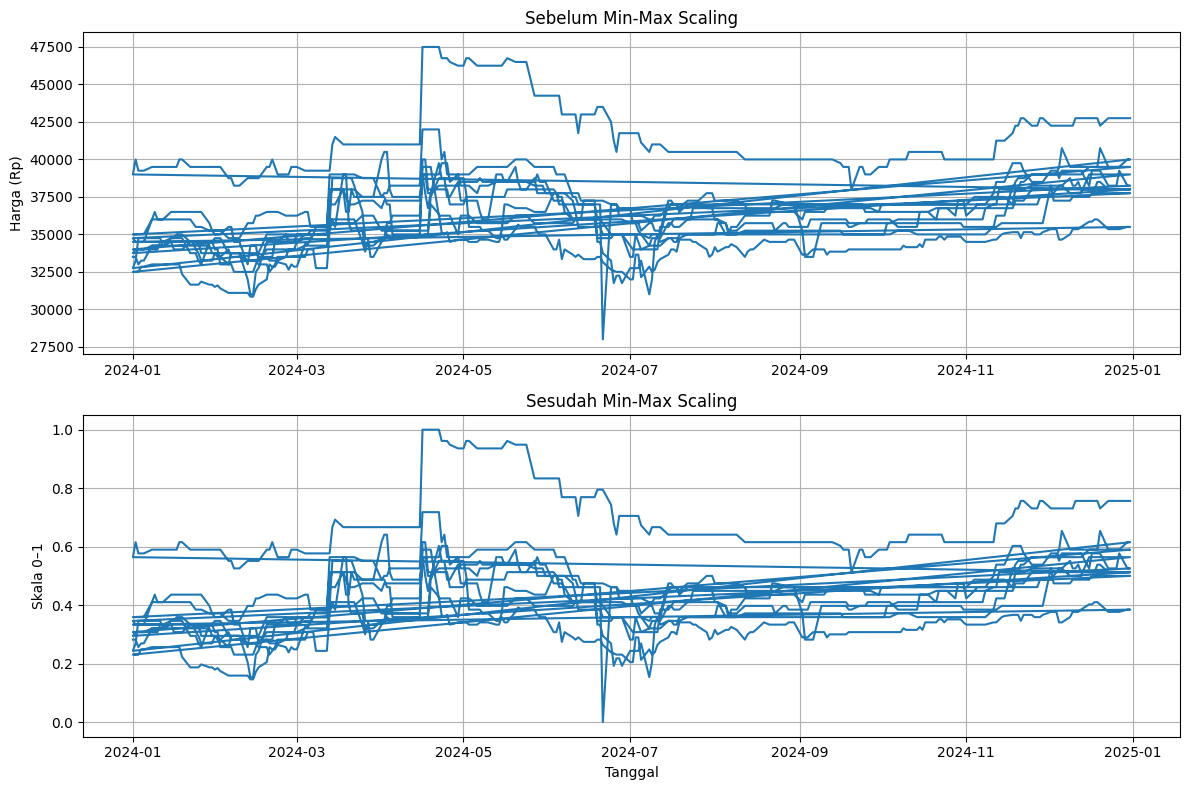

In [60]:
import matplotlib.pyplot as plt

# Memilih satu komoditas sebagai contoh
komoditas_pilihan = "Bawang Putih Ukuran Sedang"

data_visual = df_pihps_long[
    df_pihps_long["komoditas"] == komoditas_pilihan
]

# Membuat dua grafik
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# Grafik harga sebelum transformasi
ax[0].plot(
    data_visual["tanggal"],
    data_visual["harga_interpolasi"]
)
ax[0].set_title("Sebelum Min-Max Scaling")
ax[0].set_ylabel("Harga (Rp)")
ax[0].grid(True)

# Grafik harga setelah transformasi
ax[1].plot(
    data_visual["tanggal"],
    data_visual["harga_minmax"]
)
ax[1].set_title("Sesudah Min-Max Scaling")
ax[1].set_ylabel("Skala 0–1")
ax[1].set_xlabel("Tanggal")
ax[1].grid(True)

plt.tight_layout()
plt.show()

In [61]:
# Memeriksa hasil Min-Max Scaling setiap komoditas
cek_scaling = df_pihps_long.groupby("komoditas")["harga_minmax"].agg(
    nilai_minimum="min",
    nilai_maksimum="max"
).reset_index()

display(cek_scaling)

,komoditas,nilai_minimum,nilai_maksimum
0,Bawang Putih Ukuran Sedang,0.0,1.0
1,Beras Kualitas Medium I,0.0,1.0
2,Cabai Rawit Merah,0.0,1.0
3,Daging Ayam Ras Segar,0.0,1.0
4,Gula Pasir Lokal,0.0,1.0


### Tahap 7 — Pemrosesan Data dalam Grup dan Jawaban Pertanyaan
##### 7.a Agregasi data menggunakan groupby()

In [62]:
# Membuat kolom bulan
df_analisis = df_pihps_long.copy()
df_analisis["bulan"] = df_analisis["tanggal"].dt.month

# Agregasi harga berdasarkan wilayah, komoditas, dan bulan
df_bulanan = df_analisis.groupby(
    ["wilayah", "komoditas", "bulan"]
).agg(
    rata_rata_harga=("harga_interpolasi", "mean"),
    harga_minimum=("harga_interpolasi", "min"),
    harga_maksimum=("harga_interpolasi", "max"),
    jumlah_pengamatan=("harga_interpolasi", "count")
).reset_index()

# Menampilkan hasil
print("Ukuran data bulanan:", df_bulanan.shape)
display(df_bulanan.head(15))

Ukuran data bulanan: (540, 7)


,wilayah,komoditas,bulan,rata_rata_harga,harga_minimum,harga_maksimum,jumlah_pengamatan
0,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,1,34032.608696,33000.0,34750.0,23
1,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,2,33738.095238,31000.0,35000.0,21
2,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,3,36107.142857,33500.0,38750.0,21
3,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,4,36409.090909,34500.0,38750.0,22
4,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,5,36250.000000,34750.0,38750.0,23
5,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,6,36050.000000,35000.0,37750.0,20
6,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,7,35467.391304,33500.0,36750.0,23
7,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,8,36278.409091,35000.0,37250.0,22
8,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,9,35273.809524,33500.0,35750.0,21
9,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,10,35739.130435,35500.0,35750.0,23


In [63]:
# Mengambil rata-rata harga Januari
harga_januari = df_bulanan[df_bulanan["bulan"] == 1][
    ["wilayah", "komoditas", "rata_rata_harga"]
].rename(columns={"rata_rata_harga": "harga_januari"})

# Mengambil rata-rata harga Desember
harga_desember = df_bulanan[df_bulanan["bulan"] == 12][
    ["wilayah", "komoditas", "rata_rata_harga"]
].rename(columns={"rata_rata_harga": "harga_desember"})

# Menggabungkan harga Januari dan Desember
df_perubahan = harga_januari.merge(
    harga_desember,
    on=["wilayah", "komoditas"],
    how="inner"
)

# Menghitung selisih dan persentase perubahan
df_perubahan["selisih_harga"] = (
    df_perubahan["harga_desember"] -
    df_perubahan["harga_januari"]
)
df_perubahan["persentase_perubahan"] = (
    df_perubahan["selisih_harga"] /
    df_perubahan["harga_januari"] * 100
)
display(df_perubahan.head(15))

,wilayah,komoditas,harga_januari,harga_desember,selisih_harga,persentase_perubahan
0,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,34032.608696,38545.454545,4512.845850,13.260358
1,Kab. Banyuwangi,Beras Kualitas Medium I,13032.608696,13238.636364,206.027668,1.580863
2,Kab. Banyuwangi,Cabai Rawit Merah,44293.478261,33659.090909,-10634.387352,-24.008924
3,Kab. Banyuwangi,Daging Ayam Ras Segar,29108.695652,31715.909091,2607.213439,8.956820
4,Kab. Banyuwangi,Gula Pasir Lokal,16280.434783,16672.727273,392.292490,2.409595
5,Kab. Jember,Bawang Putih Ukuran Sedang,32426.086957,35418.181818,2992.094862,9.227431
6,Kab. Jember,Beras Kualitas Medium I,14304.347826,14102.272727,-202.075099,-1.412683
7,Kab. Jember,Cabai Rawit Merah,44476.086957,34681.818182,-9794.268775,-22.021426
8,Kab. Jember,Daging Ayam Ras Segar,28652.173913,32118.181818,3466.007905,12.096841
9,Kab. Jember,Gula Pasir Lokal,16700.000000,16329.545455,-370.454545,-2.218291


In [64]:
# Mencari kenaikan tertinggi untuk setiap komoditas
kenaikan_per_komoditas = (
    df_perubahan.loc[
        df_perubahan.groupby("komoditas")[
            "persentase_perubahan"
        ].idxmax()
    ]
    .sort_values("persentase_perubahan", ascending=False)
)

print("Kenaikan tertinggi setiap komoditas:")
display(kenaikan_per_komoditas)

# Mencari kenaikan tertinggi secara keseluruhan
kenaikan_tertinggi = df_perubahan.loc[
    df_perubahan["persentase_perubahan"].idxmax()
]

print("\nKenaikan harga tertinggi secara keseluruhan:")
display(kenaikan_tertinggi.to_frame(name="Nilai"))

Kenaikan tertinggi setiap komoditas:


,wilayah,komoditas,harga_januari,harga_desember,selisih_harga,persentase_perubahan
10,Kab. Sumenep,Bawang Putih Ukuran Sedang,34456.521739,39534.090909,5077.569170,14.736163
43,Kota Surabaya,Daging Ayam Ras Segar,31260.869565,35056.818182,3795.948617,12.142812
19,Kota Blitar,Gula Pasir Lokal,15782.608696,17400.000000,1617.391304,10.247934
16,Kota Blitar,Beras Kualitas Medium I,12560.869565,13388.636364,827.766798,6.590044
22,Kota Kediri,Cabai Rawit Merah,44826.086957,46750.000000,1923.913043,4.291950



Kenaikan harga tertinggi secara keseluruhan:


,Nilai
wilayah,Kab. Sumenep
komoditas,Bawang Putih Ukuran Sedang
harga_januari,34456.521739
harga_desember,39534.090909
selisih_harga,5077.56917
persentase_perubahan,14.736163


##### 7.b Visualisasi

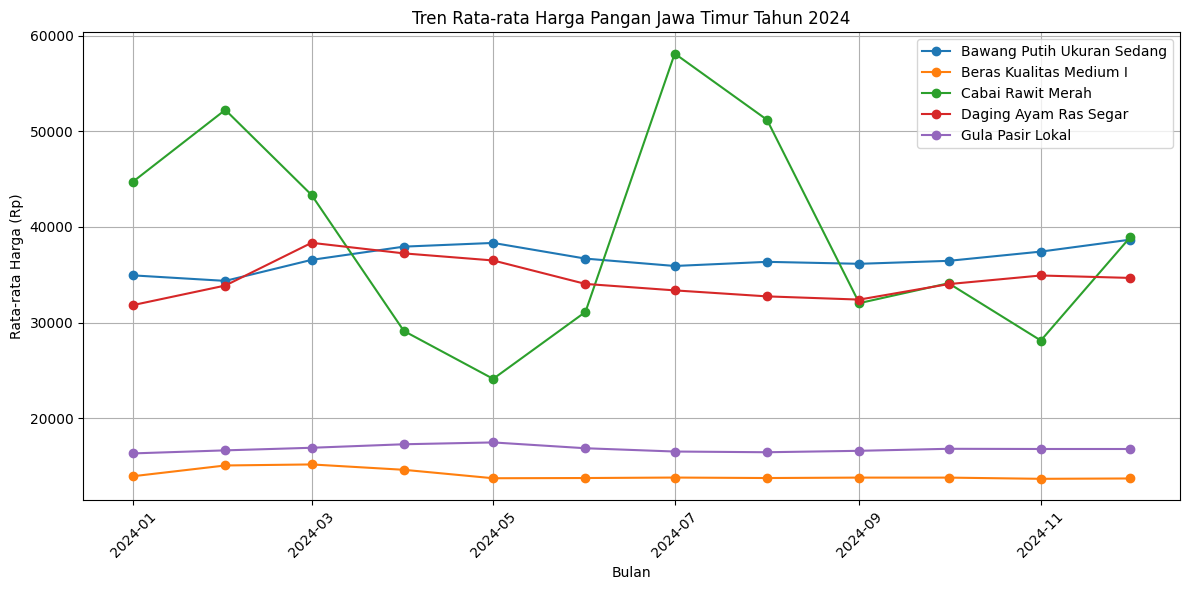

In [65]:
import matplotlib.pyplot as plt

# Menghitung rata-rata harga bulanan setiap komoditas
df_tren_bulanan = (
    df_pihps_long
    .groupby([
        "komoditas",
        pd.Grouper(key="tanggal", freq="MS")
    ])["harga_interpolasi"]
    .mean()
    .reset_index()
)

# Membuat grafik garis
plt.figure(figsize=(12, 6))

for komoditas in df_tren_bulanan["komoditas"].unique():
    data = df_tren_bulanan[
        df_tren_bulanan["komoditas"] == komoditas
    ]

    plt.plot(
        data["tanggal"],
        data["harga_interpolasi"],
        marker="o",
        label=komoditas
    )

plt.title("Tren Rata-rata Harga Pangan Jawa Timur Tahun 2024")
plt.xlabel("Bulan")
plt.ylabel("Rata-rata Harga (Rp)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

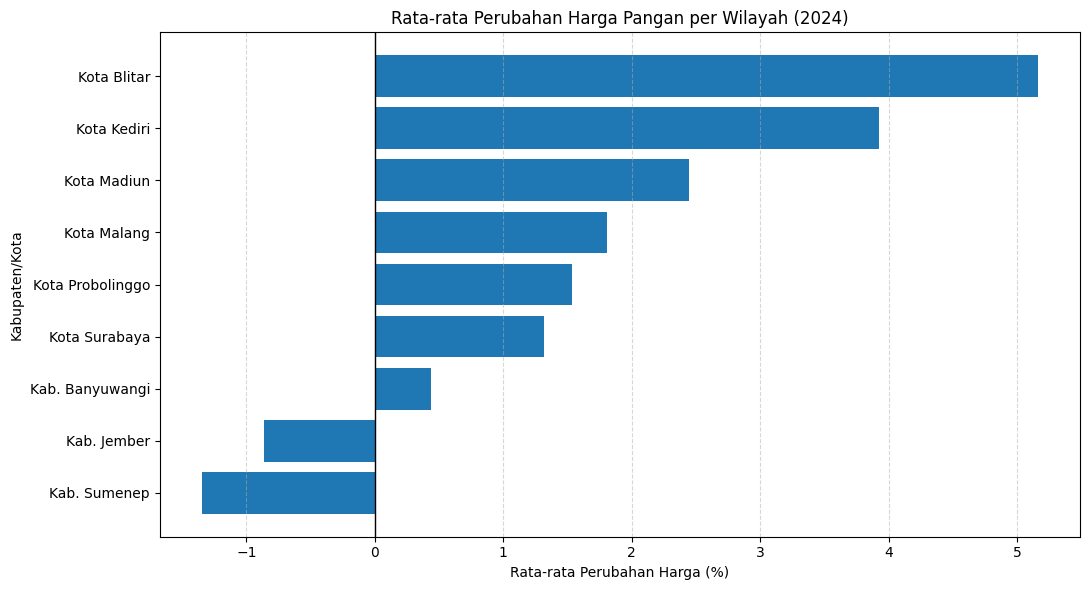

In [66]:
import matplotlib.pyplot as plt

# Menghitung rata-rata persentase perubahan 5 komoditas
df_perubahan_wilayah = (
    df_perubahan
    .groupby("wilayah")["persentase_perubahan"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(11, 6))

plt.barh(
    df_perubahan_wilayah.index,
    df_perubahan_wilayah.values
)

plt.axvline(x=0, color="black", linewidth=1)
plt.title("Rata-rata Perubahan Harga Pangan per Wilayah (2024)")
plt.xlabel("Rata-rata Perubahan Harga (%)")
plt.ylabel("Kabupaten/Kota")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [67]:
# Membuat pivot table persentase perubahan harga
df_pivot = df_perubahan.pivot_table(
    index="wilayah",
    columns="komoditas",
    values="persentase_perubahan"
)

display(df_pivot.round(2))

komoditas,Bawang Putih Ukuran Sedang,Beras Kualitas Medium I,Cabai Rawit Merah,Daging Ayam Ras Segar,Gula Pasir Lokal
wilayah,,,,,
Kab. Banyuwangi,13.26,1.58,-24.01,8.96,2.41
Kab. Jember,9.23,-1.41,-22.02,12.10,-2.22
Kab. Sumenep,14.74,-12.35,-14.68,2.10,3.45
Kota Blitar,14.11,6.59,-15.34,10.21,10.25
Kota Kediri,6.16,-4.08,4.29,10.24,2.99
Kota Madiun,10.14,-5.55,-5.72,10.06,3.30
Kota Malang,10.75,1.82,-12.61,7.32,1.74
Kota Probolinggo,10.67,-1.62,-12.09,9.24,1.46
Kota Surabaya,7.74,0.37,-16.00,12.14,2.35


In [68]:
print("Kolom df_gabungan:")
print(df_gabungan.columns.tolist())
print("Kolom df_ref_wilayah:")
print(df_ref_wilayah.columns.tolist())
print("\nIsi 5 baris pertama:")
display(df_ref_wilayah.head())

Kolom df_gabungan:
['kode', 'wilayah', 'komoditas', 'minggu', 'harga_rata_rata', 'TEMP_C', 'DEWP_C', 'MAX_C', 'MIN_C', 'SLP', 'STP', 'VISIB', 'WDSP', 'PRCP_mm', 'nama_resmi', 'luas', 'total', 'kepadatan_penduduk', 'jumlah_kecamatan', 'jumlah_kelurahan', 'jumlah_desa']
Kolom df_ref_wilayah:
['kode', 'nama', 'luas', 'total', 'jumlah_kecamatan', 'jumlah_kelurahan', 'jumlah_desa', 'kepadatan_penduduk']

Isi 5 baris pertama:


,kode,nama,luas,total,jumlah_kecamatan,jumlah_kelurahan,jumlah_desa,kepadatan_penduduk
0,35.01,Kabupaten Pacitan,1434.818,588718,12,5,167.0,410.308485
1,35.02,Kabupaten Ponorogo,1418.618,979008,21,26,281.0,690.113900
2,35.03,Kabupaten Trenggalek,1249.367,753810,14,5,152.0,603.353538
3,35.04,Kabupaten Tulungagung,1144.856,1139224,19,14,257.0,995.080604
4,35.05,Kabupaten Blitar,1745.383,1261699,22,28,220.0,722.878016


In [69]:
# Menghitung rata-rata persentase perubahan harga per wilayah
perubahan_wilayah = (
    df_perubahan
    .groupby("wilayah", as_index=False)
    .agg(
        rata_rata_perubahan=("persentase_perubahan", "mean")
    )
)

# Mengambil informasi karakteristik wilayah
info_wilayah = df_ref_wilayah.copy()

# Menghitung kepadatan penduduk per km persegi
info_wilayah["kepadatan_penduduk"] = (
    info_wilayah["total"] / info_wilayah["luas"]
)

# Menambahkan kode wilayah berdasarkan pemetaan sebelumnya
perubahan_wilayah["kode"] = (
    perubahan_wilayah["wilayah"].map(pemetaan_wilayah)
)

# Menyamakan tipe data kode agar bisa digabungkan
perubahan_wilayah["kode"] = pd.to_numeric(
    perubahan_wilayah["kode"]
)

info_wilayah["kode"] = pd.to_numeric(
    info_wilayah["kode"]
)

# Menggabungkan data perubahan harga dan karakteristik wilayah
df_perbandingan = perubahan_wilayah.merge(
    info_wilayah[
        [
            "kode",
            "nama",
            "luas",
            "total",
            "kepadatan_penduduk",
            "jumlah_kecamatan",
            "jumlah_kelurahan",
            "jumlah_desa"
        ]
    ],
    on="kode",
    how="left"
)

display(
    df_perbandingan.sort_values(
        "rata_rata_perubahan",
        ascending=False
    ).round(2)
)


,wilayah,rata_rata_perubahan,kode,nama,luas,total,kepadatan_penduduk,jumlah_kecamatan,jumlah_kelurahan,jumlah_desa
3,Kota Blitar,5.16,35.72,Kota Blitar,33.20,161204,4855.10,3,21,NaN
4,Kota Kediri,3.92,35.71,Kota Kediri,67.23,301424,4483.34,3,46,NaN
5,Kota Madiun,2.44,35.77,Kota Madiun,36.13,201733,5584.15,3,27,NaN
6,Kota Malang,1.80,35.73,Kota Malang,111.08,889359,8006.69,5,57,NaN
7,Kota Probolinggo,1.54,35.74,Kota Probolinggo,55.20,243746,4415.93,5,29,NaN
8,Kota Surabaya,1.32,35.78,Kota Surabaya,338.05,3018022,8927.79,31,153,NaN
0,Kab. Banyuwangi,0.44,35.10,Kabupaten Banyuwangi,3593.85,1791789,498.57,25,28,189.0
1,Kab. Jember,-0.87,35.09,Kabupaten Jember,3314.36,2615874,789.26,31,22,226.0
2,Kab. Sumenep,-1.35,35.29,Kabupaten Sumenep,2083.05,1143002,548.72,27,4,330.0


In [70]:
# Mengurutkan wilayah berdasarkan rata-rata perubahan harga
hasil_akhir_wilayah = df_perbandingan[
    ["wilayah", "rata_rata_perubahan"]
].sort_values(
    "rata_rata_perubahan",
    ascending=False
)

display(hasil_akhir_wilayah.round(2))

,wilayah,rata_rata_perubahan
3,Kota Blitar,5.16
4,Kota Kediri,3.92
5,Kota Madiun,2.44
6,Kota Malang,1.80
7,Kota Probolinggo,1.54
8,Kota Surabaya,1.32
0,Kab. Banyuwangi,0.44
1,Kab. Jember,-0.87
2,Kab. Sumenep,-1.35


In [71]:
from scipy.stats import pearsonr, spearmanr

# Variabel karakteristik wilayah yang akan diuji
variabel_wilayah = [
    "kepadatan_penduduk",
    "jumlah_kecamatan",
    "jumlah_kelurahan",
    "jumlah_desa"
]

hasil_korelasi = []

for variabel in variabel_wilayah:

    # Mengambil data yang tidak kosong
    data_korelasi = df_perbandingan[
        ["rata_rata_perubahan", variabel]
    ].dropna()

    n = len(data_korelasi)

    # Menghitung koefisien korelasi
    if n >= 3:
        r_pearson, p_pearson = pearsonr(
            data_korelasi["rata_rata_perubahan"],
            data_korelasi[variabel]
        )

        rho_spearman, p_spearman = spearmanr(
            data_korelasi["rata_rata_perubahan"],
            data_korelasi[variabel]
        )
    else:
        r_pearson = float("nan")
        p_pearson = float("nan")
        rho_spearman = float("nan")
        p_spearman = float("nan")

    # P-value tidak ditafsirkan jika jumlah data kurang dari 5
    if n < 5:
        p_pearson = float("nan")
        p_spearman = float("nan")

    hasil_korelasi.append({
        "Variabel Wilayah": variabel,
        "Jumlah Wilayah": n,
        "Pearson (r)": r_pearson,
        "P-value Pearson": p_pearson,
        "Spearman (rho)": rho_spearman,
        "P-value Spearman": p_spearman
    })

# Membuat tabel hasil korelasi
tabel_korelasi = pd.DataFrame(hasil_korelasi)

display(tabel_korelasi.round(4))

,Variabel Wilayah,Jumlah Wilayah,Pearson (r),P-value Pearson,Spearman (rho),P-value Spearman
0,kepadatan_penduduk,9,0.5179,0.1532,0.5500,0.1250
1,jumlah_kecamatan,9,-0.7848,0.0122,-0.8806,0.0017
2,jumlah_kelurahan,9,0.0983,0.8014,0.2167,0.5755
3,jumlah_desa,3,-0.8642,NaN,-1.0000,NaN


### Interpretasi Hasil Korelasi

Berdasarkan hasil pengujian menggunakan metode Pearson dan Spearman terhadap sembilan wilayah, diperoleh hasil sebagai berikut:

1. **Kepadatan Penduduk**  
   Memiliki korelasi positif sedang dengan rata-rata perubahan harga pangan. Nilai Pearson sebesar 0,5179 dan Spearman sebesar 0,5500. Namun, nilai p-value kedua metode lebih besar dari 0,05, sehingga belum terdapat bukti statistik yang cukup untuk menyatakan adanya hubungan yang signifikan.

2. **Jumlah Kecamatan**  
   Memiliki korelasi negatif kuat dengan rata-rata perubahan harga pangan. Nilai Pearson sebesar -0,7848 dan Spearman sebesar -0,8806. Kedua nilai p-value lebih kecil dari 0,05, sehingga terdapat hubungan yang signifikan secara statistik pada data yang dianalisis.

3. **Jumlah Kelurahan**  
   Memiliki korelasi positif yang sangat lemah. Nilai Pearson sebesar 0,0983 dan Spearman sebesar 0,2167. Nilai p-value kedua metode lebih besar dari 0,05, sehingga belum terdapat bukti statistik yang cukup untuk menyatakan adanya hubungan yang signifikan.

4. **Jumlah Desa**  
   Memiliki nilai Pearson sebesar -0,8642 dan Spearman sebesar -1,0000. Namun, perhitungan hanya menggunakan tiga wilayah sehingga hasilnya belum cukup untuk dijadikan dasar kesimpulan statistik yang dapat diandalkan.

### Kesimpulan Analisis Korelasi

Berdasarkan hasil pengujian, jumlah kecamatan memiliki hubungan negatif yang kuat dan signifikan secara statistik dengan rata-rata perubahan harga pangan pada sembilan wilayah yang dianalisis. Sementara itu, kepadatan penduduk dan jumlah kelurahan belum menunjukkan hubungan yang signifikan secara statistik. Jumlah desa belum dapat disimpulkan karena keterbatasan jumlah data.

Hasil ini menunjukkan adanya hubungan statistik antara jumlah kecamatan dan perubahan harga pangan pada sampel yang digunakan. Namun, korelasi tidak menunjukkan hubungan sebab-akibat. Selain itu, jumlah wilayah yang terbatas membuat hasil analisis perlu ditafsirkan secara hati-hati.